# Operational thresholds for long-range entanglement in quantum networks

Code for every computed figure and number in the main text and the Supplemental Material.

**Physical Review version (`APS1.tex`, `supplementary.tex`).** Sections 12 and 13 write every figure of the
submission to `figures2/` as vector PDFs drawn at their printed size, with lettering of at least 8 pt (2 mm),
lines of at least 0.5 pt and panel labels inside the figures:

| Figure | File | Section |
|---|---|---|
| Figs. 1 and 2 (schematics) | `fig1.pdf`, `fig2.pdf` | 12 |
| Figs. 3 and 4 (one column) | `fig3.pdf`, `fig4.pdf` | 12 |
| Fig. 5 (two columns) | `fig5.pdf` | 12 |
| Figs. S1-S4 (Supplemental Material) | `figS1.pdf` ... `figS4.pdf` | 13 |

Upload `figures2/` next to `APS1.tex` and `supplementary.tex`.

**Earlier single-column version.** Sections 3-10 also write the PNG figures of the earlier version to `figures/`:

| Figure | File | Section |
|---|---|---|
| Fig. 3(a), 4(a) | `f4.png`, `f5.png` | 3 |
| Fig. 3(b) | `f6.png` | 4 |
| Fig. 4(b) and the star in its caption | `f8.png`, `star8.png` | 5 |
| Fig. 5 | `PMF_distributions.png` | 6 |
| Fig. S1(a), S1(b) | `flower23.png`, `flower24.png` | 7 |
| Fig. S2 | `CSD_scaling.png` | 8 |
| Fig. S3(a), S3(b) and Table S1 | `f7.png`, `f9.png` | 9 |
| Fig. S4 | `EXn_scaling.png` | 10 |

The schematics `f1.png`, `f2.png` and `f3.png` of that version were drawn by hand.

**Run time.** Everything takes a few minutes except the 101 × 101 concurrence-threshold grid (Section 5), which takes
several hours. It is cached in `data/cth_pmf_U2V2_101x101.csv`; set `RECOMPUTE_CTH = True` to rebuild it.

In [1]:
import os, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.markers import MarkerStyle
from matplotlib.patches import ConnectionPatch
from matplotlib.path import Path
from matplotlib.transforms import Affine2D
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import distance_transform_edt
from PIL import Image

FIG_DIR, DATA_DIR = "figures", "data"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

# House style (as in the original notebook)
plt.rcParams.update({"font.size": 14, "axes.labelsize": 18,
                     "xtick.labelsize": 14, "ytick.labelsize": 14,
                     "figure.dpi": 100})
SAVE_DPI = 500
LABEL_FS, TICK_FS = 20, 16
FIG_SCALE = 1.0      # figure size multiplier (0.7 for the two-column APS version in figures2/)
END_FS = 11          # font size of the boundary end-point labels
LEGEND_FS = TICK_FS  # legend font size of the fixed-point flows
LEGEND_LOC = "upper left"   # None: no legend
END_TOP_HA = "center"    # alignment of the (27/32, 1) label above the boundary end point
RED, DARKRED = "tab:red", "#8b0000"


def save(fig, name, dpi=SAVE_DPI, **kw):
    """Save as an opaque RGB PNG (an alpha channel shows up as a grey box in some PDF viewers)."""
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=dpi, bbox_inches="tight", **kw)
    im = Image.open(path).convert("RGBA")
    flat = Image.new("RGB", im.size, "white")
    flat.paste(im, mask=im.getchannel("A"))
    flat.save(path)
    print("saved", path)


def corner_ylabel(ax, text, fs=LABEL_FS, x=-0.06, y=1.05):
    """Horizontal y-label above the top-left corner of the axes (house style)."""
    ax.set_ylabel(text, rotation=0, fontsize=fs)
    ax.yaxis.set_label_coords(x, y)


def side_cbar_label(fig, cbar, text, fs=LABEL_FS, dx=0.48):
    """Horizontal colour-bar label (one mathtext string), dx inches to the right of the bar."""
    fig.canvas.draw()
    bb = cbar.ax.get_position()
    fig.text(bb.x1 + dx / fig.get_figwidth(), 0.5 * (bb.y0 + bb.y1), text, fontsize=fs, ha="left", va="center")

## 1. Model

Series and parallel rules of ideal concurrence percolation (Section S1), the exact survival recursion (Eq. 2, and Eq. S7 for a general $(U,V)$-flower), the asymptotic survival probability $S_\infty$ obtained by iterating from $S_0=1$, and the operational boundary. For the $(2,2)$-flower the boundary is $\eta_p = 2-\tfrac{32}{27}\eta_s$ with $S_\infty=3/(4\eta_s)$ on it (Eq. 3). For general flowers it is found numerically from the condition that the two non-zero fixed points merge.

In [2]:
# ---------- series and parallel rules (Supplementary Materials, Section S1) ----------
def lam1(c):
    """Larger Schmidt coefficient of a link with concurrence c."""
    return 0.5 * (1.0 + np.sqrt(np.clip(1.0 - np.asarray(c, float) ** 2, 0.0, 1.0)))


def S_hat(c1, c2):
    return np.asarray(c1) * np.asarray(c2)


def P_hat(c1, c2):
    M = np.maximum(0.5, lam1(c1) * lam1(c2))
    return 2.0 * np.sqrt(np.clip(M * (1.0 - M), 0.0, None))


# ---------- exact survival recursion, Eq. (2) / Eq. (S7) ----------
def survival_map(S, eta_s, eta_p, U=2, V=2):
    PU = eta_s ** (U - 1) * S ** U
    PV = eta_s ** (V - 1) * S ** V
    return PU + PV - (2.0 - eta_p) * PU * PV


def S_inf(eta_s, eta_p, U=2, V=2, tol=1e-14, max_iter=200000, chunk=50):
    """S_infinity: iterate Eq. (2) from S_0 = 1 (works on scalars or arrays).

    Points still moving after each chunk of iterations are kept in a shrinking active set,
    so the slow points next to the boundary do not hold up the rest of the grid.
    """
    es, ep = np.broadcast_arrays(np.asarray(eta_s, float), np.asarray(eta_p, float))
    S = np.ones(es.size)
    act = np.arange(es.size)
    e_s, e_p, s = es.ravel(), ep.ravel(), S.copy()
    for _ in range(0, max_iter, chunk):
        for _ in range(chunk - 1):
            s = survival_map(s, e_s, e_p, U, V)
        s_new = survival_map(s, e_s, e_p, U, V)
        moving = np.abs(s_new - s) >= tol
        S[act] = s_new
        act, e_s, e_p, s = act[moving], e_s[moving], e_p[moving], s_new[moving]
        if act.size == 0:
            break
    S = S.reshape(es.shape)
    return S if S.ndim else float(S)


# ---------- (2,2) phase boundary, Eq. (3) ----------
def boundary_22(eta_s):
    return 2.0 - 32.0 / 27.0 * np.asarray(eta_s, float)


def boundary_curve(U, V, n_pts=1500):
    """Operational boundary (eta_s, eta_p) of a (U,V)-flower and the merged fixed point S* on it.

    On the boundary the two non-zero fixed points of Eq. (S7) merge: f(S)=R(S)-S=0 and f'(S)=0.
    Eliminating eta_p with f(S)=0 leaves one equation in S for each eta_s.
    """
    es_out, ep_out, s_out = [], [], []
    S = np.linspace(1e-6, 1 - 1e-9, 20001)
    for es in np.linspace(0.5, 1.0, n_pts):
        PU, PV = es ** (U - 1) * S ** U, es ** (V - 1) * S ** V
        ep = 2.0 - (PU + PV - S) / (PU * PV)
        dU, dV = U * PU / S, V * PV / S
        g = dU + dV - (2.0 - ep) * (dU * PV + PU * dV) - 1.0
        ok = (ep >= 0) & (ep <= 1)
        k = np.flatnonzero(ok[:-1] & ok[1:] & (np.sign(g[:-1]) != np.sign(g[1:])))
        if k.size:
            i = k[-1]                        # root on the upper (surviving) branch
            t = g[i] / (g[i] - g[i + 1])
            s_star = S[i] + t * (S[i + 1] - S[i])
            es_out.append(es); s_out.append(s_star)
            ep_out.append(np.interp(s_star, S[i:i + 2], ep[i:i + 2]))
    return np.array(es_out), np.array(ep_out), np.array(s_out)

## 2. Distribution of $X_n$ and the concurrence threshold

The full distribution of $X_n$ is propagated on a uniform grid of `n_bins` points, together with the failure probability $\mathbb{P}(X_n=0)$, using one series step per branch and one parallel step per renormalisation (Section S5). The concurrence threshold is the smallest $c_0$ for which the mass in the top four bins at $n=50$ reaches half its value for perfect links, located by bracketing and bisection.

In [3]:
# Binned PMF engine (Supplementary Materials, Section S5).
# A distribution is stored sparsely as (idx, p, p0): grid indices idx on x_i = i/(n_bins-1),
# their probabilities p, and the failure probability p0 = P(X_n = 0) = 1 - S_n.
_PARA_TAB = {}


def _round_idx(x, n_bins):
    n1 = n_bins - 1
    return np.clip((x * n1 + 0.5).astype(np.int64), 0, n1).astype(np.int32)


def para_table(n_bins):
    """Grid index of P_hat(x_i, x_j) for every pair of grid points (cached)."""
    if n_bins not in _PARA_TAB:
        x = np.linspace(0.0, 1.0, n_bins)
        _PARA_TAB[n_bins] = _round_idx(P_hat(x[:, None], x[None, :]), n_bins)
    return _PARA_TAB[n_bins]


def _prune(idx, p, p_min):
    if p_min > 0 and idx.size:
        keep = p >= p_min
        idx, p = idx[keep], p[keep]
    order = np.argsort(idx)
    return idx[order], p[order]


def _rescale(p, mass):
    s = p.sum()
    return p * (mass / s) if s > 0 else p


def _product(idxA, pA, idxB, pB, n_bins):
    """Distribution of the product of two independent values (series rule)."""
    n1 = n_bins - 1
    ij = idxA[:, None].astype(np.int64) * idxB[None, :].astype(np.int64)
    out = np.bincount(((2 * ij + n1) // (2 * n1)).ravel(),
                      weights=(pA[:, None] * pB[None, :]).ravel(), minlength=n_bins)
    nz = np.flatnonzero(out > 0)
    return nz.astype(np.int32), out[nz]


def _parallel(idxA, pA, idxB, pB, n_bins):
    """Distribution of P_hat of two independent values (parallel rule)."""
    out = np.bincount(para_table(n_bins)[np.ix_(idxA, idxB)].ravel(),
                      weights=(pA[:, None] * pB[None, :]).ravel(), minlength=n_bins)
    nz = np.flatnonzero(out > 0)
    return nz.astype(np.int32), out[nz]


def series_branch(idx, p, p0, L, eta_s, n_bins, p_min):
    """Branch of L subnetworks joined by L-1 series operations."""
    q_branch = (1.0 - p0) ** L * eta_s ** (L - 1)
    if idx.size == 1:                                    # delta: product is again a delta
        x = idx[0] / (n_bins - 1)
        return np.array([int(x ** L * (n_bins - 1) + 0.5)], np.int32), np.array([q_branch]), 1.0 - q_branch
    cur_idx, cur_p = idx, p
    for _ in range(L - 1):
        cur_idx, cur_p = _prune(*_product(cur_idx, cur_p, idx, p, n_bins), p_min)
    return cur_idx, _rescale(cur_p, q_branch), 1.0 - q_branch


def parallel_step(iU, pU, p0U, iV, pV, p0V, eta_p, n_bins, p_min):
    """Combine the two branches: one survivor passes through, two survivors are combined w.p. eta_p."""
    out = np.zeros(n_bins)
    out[iU] += p0V * pU
    out[iV] += p0U * pV
    qU, qV = 1.0 - p0U, 1.0 - p0V
    if qU > 0 and qV > 0 and eta_p > 0 and iU.size and iV.size:
        iP, pP = _parallel(iU, pU, iV, pV, n_bins)
        out[iP] += _rescale(pP, eta_p * qU * qV)
    nz = np.flatnonzero(out > 0)
    idx, p = _prune(nz.astype(np.int32), out[nz], p_min)
    return idx, p, 1.0 - p.sum()


def pmf_evolution(c0, eta_s, eta_p, n_max, U=2, V=2, n_bins=2001, p_min=1e-12):
    """Yield (n, idx, p, p0) for n = 0..n_max, starting from identical links of concurrence c0."""
    idx = np.array([int(c0 * (n_bins - 1) + 0.5)], np.int32)
    p, p0 = np.array([1.0]), 0.0
    yield 0, idx, p, p0
    for n in range(1, n_max + 1):
        iU, pU, p0U = series_branch(idx, p, p0, U, eta_s, n_bins, p_min)
        iV, pV, p0V = series_branch(idx, p, p0, V, eta_s, n_bins, p_min)
        idx, p, p0 = parallel_step(iU, pU, p0U, iV, pV, p0V, eta_p, n_bins, p_min)
        yield n, idx, p, p0


def pmf_at(c0, eta_s, eta_p, n, **kw):
    for out in pmf_evolution(c0, eta_s, eta_p, n, **kw):
        pass
    return out[1:]


def pmf_mean(idx, p, n_bins):
    return float(np.sum(idx / (n_bins - 1) * p))

In [4]:
# Concurrence threshold from the full distribution (Supplementary Materials, Section S5):
# smallest c0 for which the mass in the top `high_bins` bins at generation n_eval reaches
# p_target times its value for perfect links, located by bracketing and bisection.
CTH_SETTINGS = dict(n_eval=50, n_bins=1001, p_target=0.5, c_tol=0.001, bisect_steps=40,
                    expand_step=0.01, expand_steps=30, p_min=1e-14, high_bins=4)


def c_th_pmf(eta_s, eta_p, c_guess=0.2, U=2, V=2, n_eval=50, n_bins=1001, p_target=0.5,
             c_tol=0.001, bisect_steps=40, expand_step=0.01, expand_steps=30, p_min=1e-14, high_bins=4):
    cache = {}
    cut = n_bins - high_bins

    def high_mass(c):
        key = round(float(c), 3)
        if key not in cache:
            idx, p, _ = pmf_at(c, eta_s, eta_p, n_eval, U=U, V=V, n_bins=n_bins, p_min=p_min)
            cache[key] = float(p[idx >= cut].sum())
        return cache[key]

    p_max = high_mass(1.0)
    if not p_max > 0:
        return np.nan
    h = lambda c: high_mass(c) - p_target * p_max

    c = float(np.clip(c_guess, 0.0, 1.0))
    hc = h(c)
    if abs(hc) < 0.05 * p_max:
        return c
    if hc >= 0:                                  # bracket downwards
        hi, lo = c, max(0.0, c - expand_step)
        for _ in range(expand_steps):
            if h(lo) < 0 or lo <= 0:
                break
            hi, lo = lo, max(0.0, lo - expand_step)
        if h(lo) >= 0:
            lo = 0.0
    else:                                        # bracket upwards
        lo, hi = c, min(1.0, c + expand_step)
        for _ in range(expand_steps):
            if h(hi) >= 0 or hi >= 1.0:
                break
            lo, hi = hi, min(1.0, hi + expand_step)
        if h(hi) < 0:
            hi = 1.0
    if not (h(lo) < 0 <= h(hi)):
        return np.nan
    for _ in range(bisect_steps):
        mid = 0.5 * (lo + hi)
        if h(mid) >= 0:
            hi = mid
        else:
            lo = mid
        if hi - lo <= c_tol:
            break
    return float(hi)

## 3. Fixed-point flows: Fig. 3(a) (`f4.png`) and Fig. 4(a) (`f5.png`)

The recursion map (solid curve) against the identity (dashed line), with fixed points marked by stars and labelled. Small arrowheads sit on the curve and show the direction of flow under iteration.

In [5]:
# Arrowhead marker: a small filled "stealth" head, centred on the curve, with no shaft.
_HEAD = Path([(-1.0, -0.75), (1.0, 0.0), (-1.0, 0.75), (-0.45, 0.0), (-1.0, -0.75)],
             [Path.MOVETO, Path.LINETO, Path.LINETO, Path.LINETO, Path.CLOSEPOLY])


def add_arrowheads(ax, x, y, F, fixed, spacing=0.2, gap=0.06, size=8, color=DARKRED):
    """Place arrowheads along the curve (x, F(x)) pointing in the direction of the flow.

    Between consecutive fixed points the iterate moves to larger x where F(x) > x and to
    smaller x where F(x) < x. Arrowheads are spread evenly in arc length, keeping clear of
    the fixed-point markers. Axes must have equal aspect and equal ranges, so data-space
    angles equal on-page angles.
    """
    arc = np.concatenate([[0.0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))])
    fixed = [float(f) for f in fixed]
    edges = sorted(set([0.0, 1.0] + fixed))
    for a, b in zip(edges[:-1], edges[1:]):
        sa, sb = np.interp([a, b], x, arc)
        # keep clear of the star markers (smaller clearance for short intervals);
        # the ends of the domain only need room for half an arrowhead
        def clearances(g):
            return (g if a in fixed else 0.016), (g if b in fixed else 0.016)
        ga, gb = clearances(gap)
        if sb - sa < ga + gb:
            ga, gb = clearances(0.042)
        if sb - sa < ga + gb:
            ga, gb = ga * (sb - sa) / (ga + gb), gb * (sb - sa) / (ga + gb)
        sa, sb = sa + ga, sb - gb
        m = max(1, int(round((sb - sa) / spacing)))
        for s in sa + (np.arange(m) + 0.5) * (sb - sa) / m:
            i = int(np.clip(np.searchsorted(arc, s), 1, len(x) - 2))
            ang = np.degrees(np.arctan2(y[i + 1] - y[i - 1], x[i + 1] - x[i - 1]))
            if F(x[i]) < x[i]:
                ang += 180.0
            ax.plot(x[i], y[i], linestyle="none", color=color, markersize=size, zorder=6,
                    marker=MarkerStyle(_HEAD, transform=Affine2D().rotate_deg(ang)))


def plot_flow(F, fixed_points, labels, var="S", curve_label=None, label_offsets=None, fname=None):
    """Recursion map F (solid) against the identity (dashed), fixed points as stars,
    flow direction as arrowheads on the curve, and labelled interior fixed points."""
    x = np.linspace(0.0, 1.0, 4001)
    y = F(x)
    fig, ax = plt.subplots(figsize=(8 * FIG_SCALE, 5 * FIG_SCALE))
    ax.plot(x, y, color=RED, lw=2.0, label=curve_label, zorder=3)
    ax.plot(x, x, color=RED, ls="--", lw=1.5, alpha=0.8, label=rf"${var}_{{n+1}}={var}_n$", zorder=2)
    fp = np.array(fixed_points, float)
    ax.plot(fp, fp, linestyle="none", marker="*", markersize=13, color=DARKRED, zorder=7, clip_on=False)
    add_arrowheads(ax, x, y, F, fp)
    for (val, text), (dx, dy) in zip(labels, label_offsets):
        ax.text(val + dx, val + dy, text, fontsize=LABEL_FS, ha="center", va="center")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal", adjustable="box")
    ticks = np.linspace(0, 1, 6)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([f"{t:.1f}" for t in ticks]); ax.set_yticklabels([f"{t:.1f}" for t in ticks])
    ax.set_xlabel(rf"${var}_n$", fontsize=LABEL_FS)
    corner_ylabel(ax, rf"${var}_{{n+1}}$")
    ax.tick_params(labelsize=TICK_FS)
    if LEGEND_LOC:                                   # (None: no legend; the caption names the curves)
        ax.legend(loc=LEGEND_LOC, frameon=True, fontsize=LEGEND_FS)
    if fname:
        save(fig, fname)
    return fig, ax

S_th = 0.690556,  S_inf = 0.938218


saved figures/f4.png


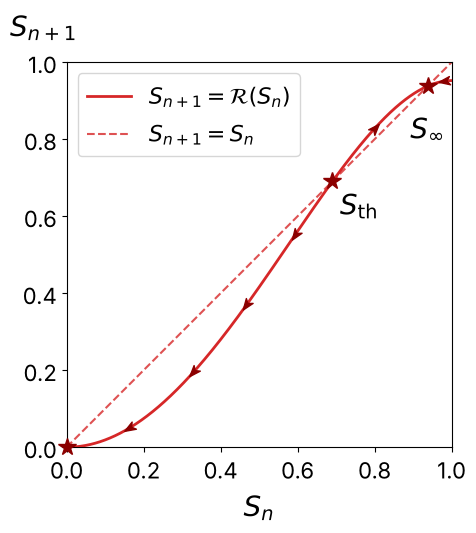

c_th (ideal) = 0.759470997087017


saved figures/f5.png


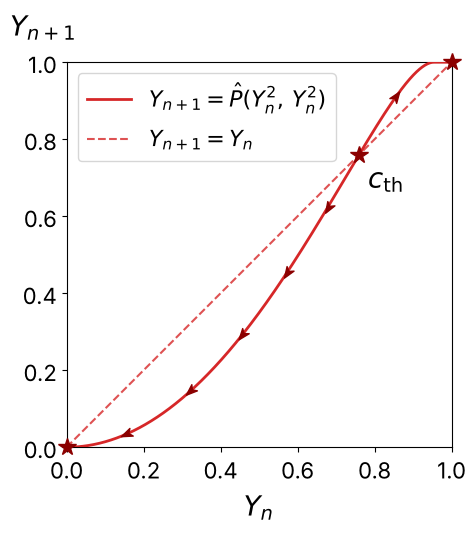

In [6]:
# Figure 3(a) (f4.png): exact survival recursion at eta_s = eta_p = 0.95
ETA_FLOW = 0.95
F_S = lambda S: survival_map(S, ETA_FLOW, ETA_FLOW)
# non-zero fixed points: roots of 1 = 2 eta_s S - (2 - eta_p) eta_s^2 S^3
roots = np.roots([-(2 - ETA_FLOW) * ETA_FLOW**2, 0.0, 2 * ETA_FLOW, -1.0])
S_th, S_star = sorted(r.real for r in roots if abs(r.imag) < 1e-12 and 0 < r.real < 1)
print(f"S_th = {S_th:.6f},  S_inf = {S_star:.6f}")


def plot_fig3a(fname):
    return plot_flow(F_S, [0.0, S_th, S_star],
                     labels=[(S_th, r"$S_{\rm th}$"), (S_star, r"$S_\infty$")],
                     label_offsets=[(0.07, -0.06), (0.0, -0.11)],
                     var="S", curve_label=r"$S_{n+1}=\mathcal{R}(S_n)$", fname=fname)


plot_fig3a("f4.png")
plt.show()

# Figure 4(a) (f5.png): ideal concurrence recursion, Eq. (5), at eta_s = eta_p = 1
F_Y = lambda Y: P_hat(S_hat(Y, Y), S_hat(Y, Y))
lo, hi = 0.5, 0.95                                   # bisection for the unstable fixed point
for _ in range(200):
    mid = 0.5 * (lo + hi)
    lo, hi = (lo, mid) if F_Y(mid) > mid else (mid, hi)
C_TH_IDEAL = 0.5 * (lo + hi)
print(f"c_th (ideal) = {C_TH_IDEAL:.15f}")


def plot_fig4a(fname):
    return plot_flow(F_Y, [0.0, C_TH_IDEAL, 1.0],
                     labels=[(C_TH_IDEAL, r"$c_{\rm th}$")], label_offsets=[(0.07, -0.06)],
                     var="Y", curve_label=r"$Y_{n+1}=\hat{P}(Y_n^2,\,Y_n^2)$", fname=fname)


plot_fig4a("f5.png")
plt.show()

## 4. Fig. 3(b): exact operational phase diagram (`f6.png`)

The exact boundary, $\eta_p = 2-\tfrac{32}{27}\eta_s$ (Eq. 3), is drawn as a thin, widely dashed black line with its end points marked, here and in Fig. 4(b). For the longer flowers of Fig. S1 the same tangency condition is solved numerically.

In [7]:
ETA_MIN, ETA_MAX = 0.80, 1.00
HEAT_TICKS = [0.80, 0.85, 0.90, 0.95, 1.00]
BOUNDARY_STYLE = dict(color="black", ls=(0, (6, 5)), lw=1.0, zorder=4)   # thin, widely spaced dashes


def style_eta_axes(ax):
    ax.set_xlim(ETA_MIN, ETA_MAX); ax.set_ylim(ETA_MIN, ETA_MAX)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks(HEAT_TICKS); ax.set_yticks(HEAT_TICKS)
    ax.set_xticklabels([f"{t:.2f}" for t in HEAT_TICKS]); ax.set_yticklabels([f"{t:.2f}" for t in HEAT_TICKS])
    ax.set_xlabel(r"$\eta_s$", fontsize=LABEL_FS)
    corner_ylabel(ax, r"$\eta_p$")
    ax.tick_params(labelsize=TICK_FS)


def heatmap(Z, eta_s_vals, eta_p_vals, vmin, vmax, cmap_name="magma"):
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("white")
    fig, ax = plt.subplots(figsize=(8 * FIG_SCALE, 5 * FIG_SCALE))
    pc = ax.pcolormesh(eta_s_vals, eta_p_vals, np.ma.masked_invalid(Z), shading="nearest",
                       cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True)
    style_eta_axes(ax)
    fig.subplots_adjust(right=0.86)
    cbar = fig.colorbar(pc, ax=ax, pad=0.03)
    cbar.ax.tick_params(labelsize=TICK_FS)
    return fig, ax, pc, cbar


def plot_S_inf_map(U=2, V=2, res=1001, vmin=0.7, fname=None, mark_ends=False):
    """Heat map of S_inf with the operational boundary as a dashed black line."""
    es = np.linspace(ETA_MIN, ETA_MAX, res)
    ES, EP = np.meshgrid(es, es, indexing="xy")
    S = S_inf(ES, EP, U, V)
    S = np.where(S > 1e-12, S, np.nan)
    fig, ax, pc, cbar = heatmap(S, es, es, vmin, 1.0)
    cbar.set_ticks(np.arange(vmin, 1.0 + 1e-9, 0.1))
    side_cbar_label(fig, cbar, r"$S_\infty$")

    # operational boundary as a dashed black line: exact formula, Eq. (3), for the (2,2)-flower,
    # and the exact tangency condition solved numerically (Eq. S7) for longer flowers
    if (U, V) == (2, 2):
        bs = np.linspace(27 / 32, 1.0, 400)
        bp = boundary_22(bs)
    else:
        bs, bp, _ = boundary_curve(U, V)
        keep = (bp >= ETA_MIN) & (bp <= 1.0)
        bs, bp = bs[keep], bp[keep]
    ax.plot(bs, bp, **BOUNDARY_STYLE)

    ax.text(0.86, 0.84, r"$S_\infty = 0$", fontsize=TICK_FS, ha="center", va="center")
    if mark_ends:
        mark_boundary_ends(ax)
    if fname:
        save(fig, fname)
    return fig, ax


def mark_boundary_ends(ax):
    """End points of the exact (2,2) boundary, Eq. (3), marked and labelled."""
    top_dx = {"center": 0.0, "left": 0.004}[END_TOP_HA]
    for (x, y), txt, (dx, dy), ha in (((27 / 32, 1.0), r"$(27/32,1)$", (top_dx, 0.007), END_TOP_HA),
                                      ((1.0, 22 / 27), r"$(1,22/27)$", (-0.006, 0.0), "right")):
        ax.plot(x, y, "o", color="black", ms=4, zorder=5, clip_on=False)
        ax.text(x + dx, y + dy, txt, fontsize=END_FS, ha=ha, va="bottom" if dy else "center")

saved figures/f6.png


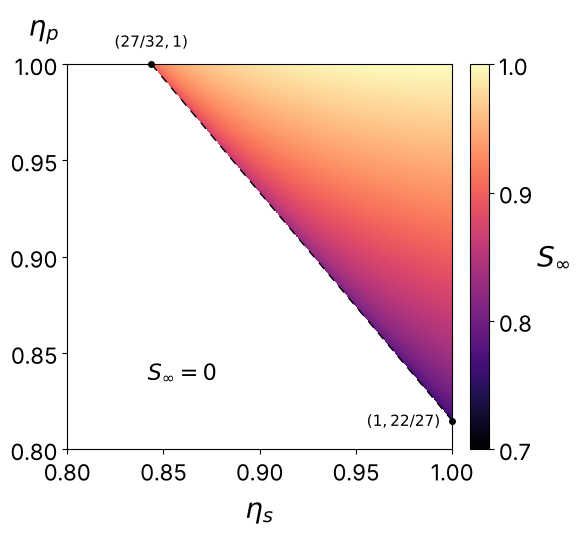

In [8]:
plot_S_inf_map(2, 2, fname="f6.png", mark_ends=True)
plt.show()

## 5. Fig. 4(b): concurrence threshold (`f8.png`, `star8.png`)

Thresholds are computed on a 101 × 101 grid (slow, cached) and interpolated onto a 1001 × 1001 grid for display.
The colour scale, 0.7 to 1.0, is the same as in Fig. 3(b). The two eight-pointed stars mark the parameters of Fig. 5;
`star8.png` is the same marker on its own, for the caption.

In [9]:
# Concurrence-threshold grid c_th(eta_s, eta_p) on a 101 x 101 grid (Supplementary Materials, S5).
# SLOW (several hours): the result is cached in data/cth_pmf_U2V2_101x101.csv and re-used.
CTH_CSV = os.path.join(DATA_DIR, "cth_pmf_U2V2_101x101.csv")
RECOMPUTE_CTH = False


def compute_cth_grid(res=101, U=2, V=2, verbose=True):
    es = np.linspace(ETA_MIN, ETA_MAX, res)
    ep = np.linspace(ETA_MIN, ETA_MAX, res)
    ES, EP = np.meshgrid(es, ep, indexing="xy")
    S = S_inf(ES, EP, U, V)
    surviving = S > 1e-12
    cth = np.full(ES.shape, np.nan)
    mid, row_seed = res // 2, 0.2                # continuation: start each row from the previous row's middle value
    for i in range(res):
        guess = row_seed
        for j in range(res):
            if surviving[i, j]:
                cth[i, j] = c_th_pmf(es[j], ep[i], c_guess=guess, U=U, V=V, **CTH_SETTINGS)
                if np.isfinite(cth[i, j]):
                    guess = cth[i, j]
        if np.isfinite(cth[i, mid]):
            row_seed = cth[i, mid]
        if verbose:
            print(f"row {i + 1}/{res} done")
    return pd.DataFrame({"eta_s": ES.ravel(), "eta_p": EP.ravel(), "c_th_pmf": cth.ravel(),
                         "S_inf": S.ravel(), "surviving": surviving.ravel().astype(int)})


if RECOMPUTE_CTH or not os.path.exists(CTH_CSV):
    compute_cth_grid().to_csv(CTH_CSV, index=False)
cth_df = pd.read_csv(CTH_CSV)
es_c = np.sort(cth_df["eta_s"].unique())
ep_c = np.sort(cth_df["eta_p"].unique())
CTH_COARSE = cth_df.pivot(index="eta_p", columns="eta_s", values="c_th_pmf").to_numpy()
print("grid", CTH_COARSE.shape, " thresholds:", np.isfinite(CTH_COARSE).sum())


def upsample(Z, xs, ys, res=1001):
    """Cubic interpolation of a coarse grid onto a fine display grid.
    Empty cells are first filled from their nearest neighbour so the surviving-phase edge
    does not ring; the exact (2,2) boundary is applied afterwards."""
    _, (ii, jj) = distance_transform_edt(~np.isfinite(Z), return_indices=True)
    interp = RegularGridInterpolator((ys, xs), Z[ii, jj], method="cubic")
    xf, yf = np.linspace(xs[0], xs[-1], res), np.linspace(ys[0], ys[-1], res)
    XF, YF = np.meshgrid(xf, yf, indexing="xy")
    Zf = interp(np.column_stack([YF.ravel(), XF.ravel()])).reshape(XF.shape)
    Zf[YF < boundary_22(XF)] = np.nan
    return xf, yf, Zf


ES_FINE, EP_FINE, CTH_FINE = upsample(CTH_COARSE, es_c, ep_c)

grid (101, 101)  thresholds: 3705


saved figures/f8.png


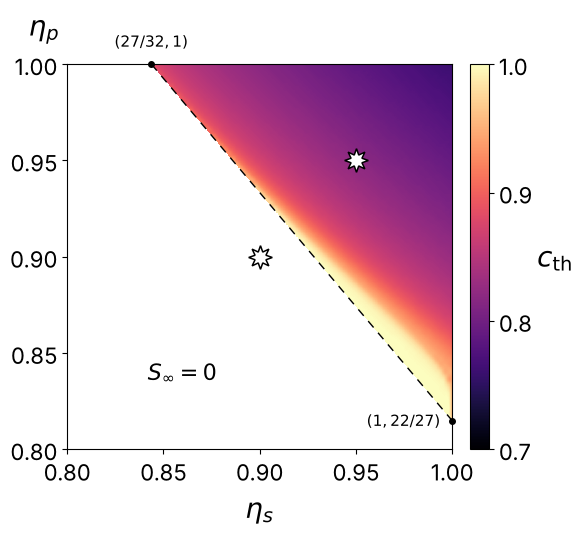

saved figures/star8.png


In [10]:
# Figure 4(b) (f8.png): concurrence threshold from the full distribution, on the same colour axis as
# Fig. 3(b), with the exact boundary (dashed) and its end points. The two eight-pointed stars mark the
# operational parameters of Fig. 5, (0.90, 0.90) and (0.95, 0.95).
STAR8 = MarkerStyle((8, 1, 0))                               # eight-pointed star
STAR8_KW = dict(marker=STAR8, ms=17, mfc="white", mec="black", mew=1.1, ls="none", zorder=6)
FIG5_POINTS = [(0.90, 0.90), (0.95, 0.95)]

def plot_cth_map(fname):
    fig, ax, pc, cbar = heatmap(np.clip(CTH_FINE, 0.7, 1.0), ES_FINE, EP_FINE, 0.7, 1.0)
    cbar.set_ticks(np.arange(0.7, 1.0 + 1e-9, 0.1))
    side_cbar_label(fig, cbar, r"$c_{\rm th}$")
    bs = np.linspace(27 / 32, 1.0, 400)
    ax.plot(bs, boundary_22(bs), **BOUNDARY_STYLE)
    mark_boundary_ends(ax)
    ax.plot(*zip(*FIG5_POINTS), **STAR8_KW)
    ax.text(0.86, 0.84, r"$S_\infty = 0$", fontsize=TICK_FS, ha="center", va="center")
    save(fig, fname)
    return fig, ax


def save_star_icon(fname):
    """The same star on its own, for the caption of Fig. 4."""
    fig = plt.figure(figsize=(0.4, 0.4))
    fig.add_axes([0, 0, 1, 1]).set_axis_off()
    fig.axes[0].plot(0, 0, **STAR8_KW)
    save(fig, fname, pad_inches=0.01)
    plt.close(fig)


plot_cth_map("f8.png")
plt.show()
save_star_icon("star8.png")

## 6. Fig. 5: distribution of $X_n$ in the three regimes (`PMF_distributions.png`)

Columns: below the operational threshold ($\eta_s=\eta_p=0.90$, $c_0=0.85$); above it but below the concurrence threshold
($\eta_s=\eta_p=0.95$, $c_0=0.80<c_{\rm th}\approx0.82$); above both ($\eta_s=\eta_p=0.95$, $c_0=0.85$).
Rows: $n=1, 5, 10$ and $n\to\infty$. Bins have width 0.025; the grey base of the first bin is $\mathbb{P}(X_n=0)=1-S_n$.
Insets (40 bins, surviving connections only) magnify the continuum at $n=5$ and, at $n=10$, the weak surviving
connections of the first two regimes and, above both thresholds, the few surviving connections just below $X=1$
(leaving out the perfect Bell pairs at exactly $X=1$). The mean $\mathbb{E}[X_n]$ (dashed) is drawn in the inset
when it lies within the inset's range, otherwise in the panel.
The large-network limit is drawn as delta functions (arrows) with weights from the exact survival theory.

Series operations shrink weak concurrences geometrically, so this figure uses a grid with the same spacing as the main
engine above $X=5\times10^{-3}$, refined geometrically below it (Section S5); $X=0$ is not a grid point.

eta=0.90 c0=0.85 n= 1: S_n=0.9090  E[X_n]=0.78797  P(X_n>=0.95)=0.0000  P(X_n=1)=0.0000
eta=0.90 c0=0.85 n= 5: S_n=0.8291  E[X_n]=0.54675  P(X_n>=0.95)=0.0348  P(X_n=1)=0.0012
eta=0.90 c0=0.85 n=10: S_n=0.7625  E[X_n]=0.00029  P(X_n>=0.95)=0.0000  P(X_n=1)=0.0000
eta=0.90 c0=0.85 n=inf: S_inf=0.0000  regime: below


eta=0.95 c0=0.80 n= 1: S_n=0.9524  E[X_n]=0.76899  P(X_n>=0.95)=0.0000  P(X_n=1)=0.0000
eta=0.95 c0=0.80 n= 5: S_n=0.9386  E[X_n]=0.61520  P(X_n>=0.95)=0.0011  P(X_n=1)=0.0000
eta=0.95 c0=0.80 n=10: S_n=0.9382  E[X_n]=0.00487  P(X_n>=0.95)=0.0000  P(X_n=1)=0.0000
eta=0.95 c0=0.80 n=inf: S_inf=0.9382  regime: between


eta=0.95 c0=0.85 n= 1: S_n=0.9524  E[X_n]=0.84242  P(X_n>=0.95)=0.0000  P(X_n=1)=0.0000
eta=0.95 c0=0.85 n= 5: S_n=0.9386  E[X_n]=0.90429  P(X_n>=0.95)=0.7542  P(X_n=1)=0.4866
eta=0.95 c0=0.85 n=10: S_n=0.9382  E[X_n]=0.93507  P(X_n>=0.95)=0.9220  P(X_n=1)=0.8939
eta=0.95 c0=0.85 n=inf: S_inf=0.9382  regime: above


saved figures/PMF_distributions.png


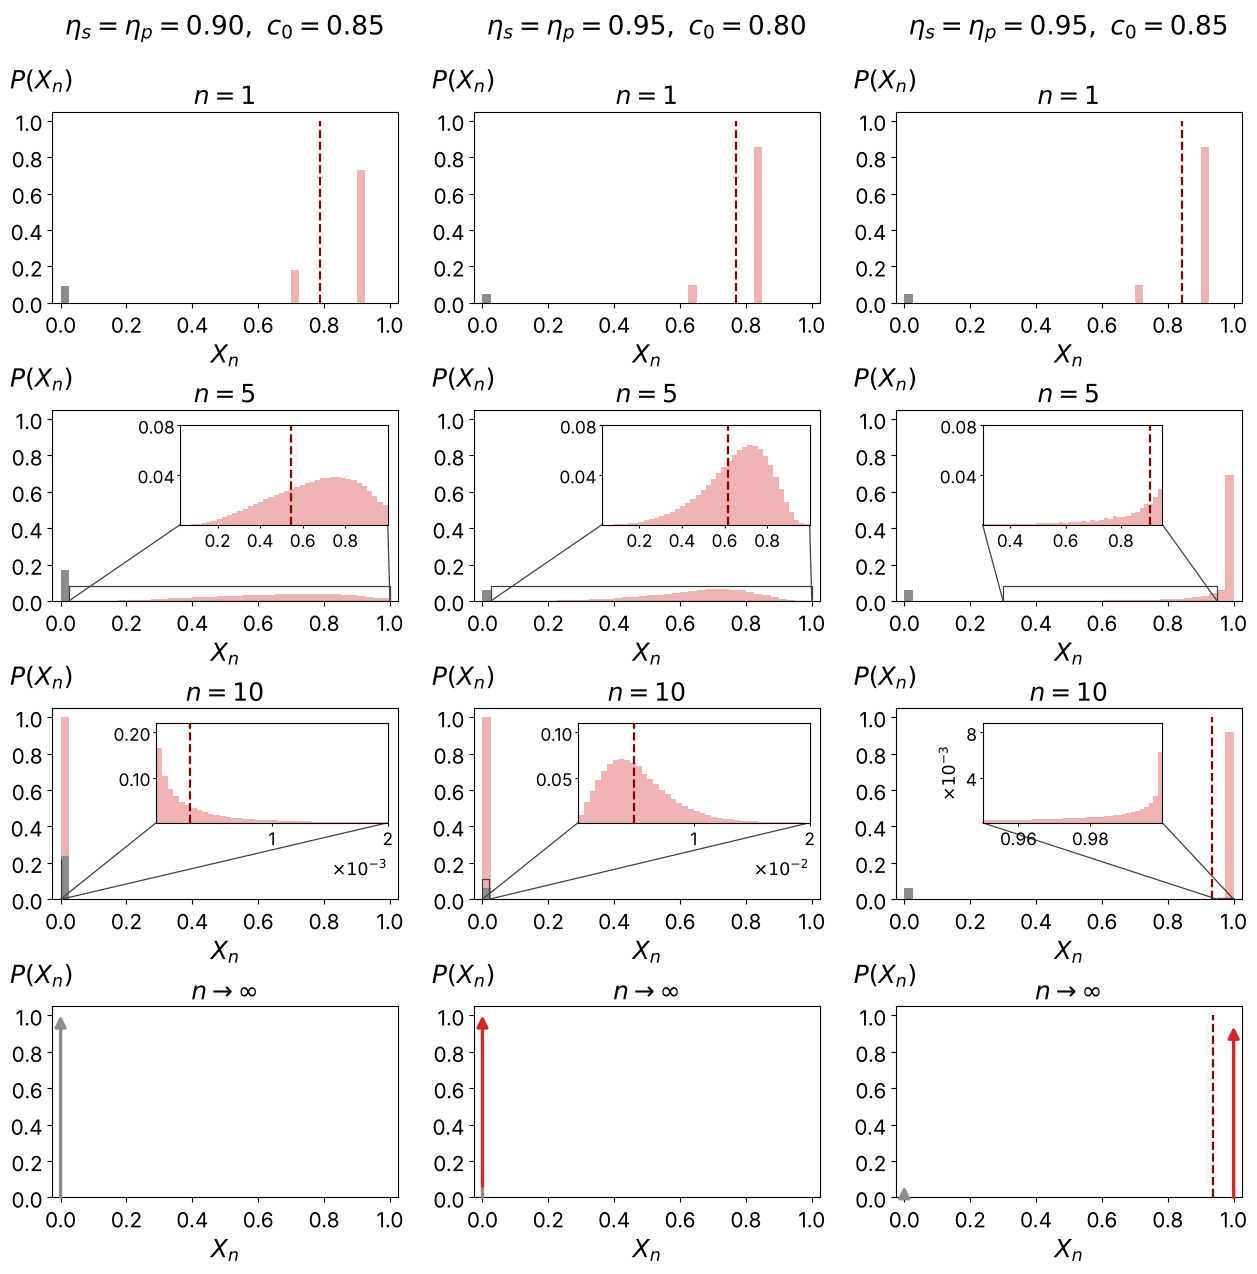

In [11]:
# Figure 5 (PMF_distributions.png): evolution of the distribution of X_n across the three regimes.
# Columns: below the operational threshold; above it but below the concurrence threshold;
# above both. Rows: n = 1, 5, 10 and the large-network limit n -> infinity (delta functions).
#
# Weak surviving connections shrink geometrically (series operations multiply concurrences), so this
# figure propagates the distribution on a grid that keeps the spacing 5e-4 of the main engine above
# X = 5e-3 and is refined geometrically (ratio 1.005) below it, down to 1e-15. X = 0 is not a grid
# point, so surviving connections can never be rounded into the failure atom P(X_n = 0).


def refined_grid(du=5e-4, x_ref=5e-3, ratio=1.005, x_min=1e-15):
    geo = x_min * ratio ** np.arange(int(np.log(x_ref / x_min) / np.log(ratio)) + 1)
    uni = np.arange(x_ref, 1.0 + du / 2, du)
    return np.unique(np.concatenate([geo[geo < x_ref - 1e-12], uni, [1.0]]))


def _nearest(grid, v):
    i = np.clip(np.searchsorted(grid, v), 1, grid.size - 1)
    return np.where(v - grid[i - 1] < grid[i] - v, i - 1, i)


def _pair_op(op, iA, pA, iB, pB, grid, chunk=400):
    """Distribution of op(A, B) for independent A, B on the grid (chunked to bound memory)."""
    out = np.zeros(grid.size)
    xB = grid[iB]
    for s in range(0, iA.size, chunk):
        v = op(grid[iA[s:s + chunk], None], xB[None, :])
        w = pA[s:s + chunk, None] * pB[None, :]
        out += np.bincount(_nearest(grid, v.ravel()), weights=w.ravel(), minlength=grid.size)
    nz = np.flatnonzero(out > 0)
    return nz, out[nz]


def pmf_evolution_grid(c0, eta_s, eta_p, n_max, grid, U=2, V=2, p_min=1e-14):
    """As pmf_evolution, on an arbitrary grid: yields (n, idx, p, p0) with values grid[idx]."""
    idx, p, p0 = _nearest(grid, np.array([c0])), np.array([1.0]), 0.0
    yield 0, idx, p, p0
    for n in range(1, n_max + 1):
        branches = []
        for L in (U, V):                                  # series: L subnetworks, L - 1 operations
            q = (1.0 - p0) ** L * eta_s ** (L - 1)
            ci, cp = idx, p
            for _ in range(L - 1):
                ci, cp = _pair_op(S_hat, ci, cp, idx, p, grid)
                keep = cp >= p_min
                ci, cp = ci[keep], cp[keep]
            branches.append((ci, cp / cp.sum() * q, q))
        (iU, pU, qU), (iV, pV, qV) = branches
        out = np.zeros(grid.size)                         # parallel: one survivor passes through,
        np.add.at(out, iU, pU * (1.0 - qV))               # two survivors are combined w.p. eta_p
        np.add.at(out, iV, pV * (1.0 - qU))
        iP, pP = _pair_op(P_hat, iU, pU, iV, pV, grid)
        out[iP] += pP / pP.sum() * eta_p * qU * qV
        idx = np.flatnonzero(out >= p_min)
        p = out[idx]
        p0 = 1.0 - p.sum()
        yield n, idx, p, p0


GRID_PMF = refined_grid()
BIN_W = 0.025                                            # histogram bin width of the main panels
EDGES = np.linspace(0.0, 1.0, int(round(1 / BIN_W)) + 1)
N_ZOOM_BINS = 40                                         # insets: 40 bins, as in the main panels
GENS = [1, 5, 10]
FAIL_C, SURV_C, SURV_A, MEAN_C = "0.55", RED, 0.35, DARKRED
# (eta_s = eta_p, c0, {n: inset}). Each inset gives its x- and y-range, its bounds in axes fraction and its
# ticks; xpow / ypow write the tick labels in units of 10^xpow / 10^ypow. Ticks are never placed at a value the
# inset leaves out (X = 0, or X = 1 for "exclude": "X=1", where the perfect Bell pairs at exactly X = 1 -- an
# atom, since the parallel rule saturates -- are left out to show the few surviving connections just below).
_N5 = dict(x=(0.025, 1.0), y=(0.0, 0.08), box=(0.37, 0.40, 0.60, 0.52),
           xticks=[0.2, 0.4, 0.6, 0.8], yticks=[0.04, 0.08])
PMF_CASES = [
    (0.90, 0.85, {5: _N5,
                  10: dict(x=(0.0, 2e-3), y=(0.0, 0.22), box=(0.30, 0.40, 0.67, 0.52),
                           xticks=[1e-3, 2e-3], xpow=-3, yticks=[0.1, 0.2])}),
    (0.95, 0.80, {5: _N5,
                  10: dict(x=(0.0, 2e-2), y=(0.0, 0.11), box=(0.30, 0.40, 0.67, 0.52),
                           xticks=[1e-2, 2e-2], xpow=-2, yticks=[0.05, 0.10])}),
    (0.95, 0.85, {5: dict(x=(0.30, 0.95), y=(0.0, 0.08), box=(0.25, 0.40, 0.52, 0.52),
                          xticks=[0.4, 0.6, 0.8], yticks=[0.04, 0.08]),
                  10: dict(x=(0.95, 1.0), y=(0.0, 0.0088), box=(0.25, 0.40, 0.52, 0.52), exclude="X=1",
                           xticks=[0.96, 0.98], yticks=[4e-3, 8e-3], ypow=-3)}),
]


GRID_LO = np.concatenate([[GRID_PMF[0]], 0.5 * (GRID_PMF[1:] + GRID_PMF[:-1])])   # rounding cell of each
GRID_HI = np.concatenate([0.5 * (GRID_PMF[1:] + GRID_PMF[:-1]), [GRID_PMF[-1]]])  # grid point


def binned(idx, p, edges):
    """Mass per bin, spreading the mass of each grid point evenly over the cell of values rounded to it
    (so that bins as narrow as the grid spacing are filled evenly)."""
    lo, hi = GRID_LO[idx], GRID_HI[idx]
    width = np.maximum(hi - lo, 1e-300)
    cdf = np.array([np.sum(p * np.clip((e - lo) / width, 0.0, 1.0)) for e in edges])
    return np.diff(cdf)


def draw_bars(ax, edges, mass, p0=None):
    """Red bars: surviving connections. Grey base of the first bar: complete failure, X_n = 0."""
    w = np.diff(edges)
    bottom = np.zeros_like(mass)
    if p0 is not None:
        ax.bar(edges[0], p0, width=w[0], align="edge", color=FAIL_C, edgecolor="none")
        bottom[0] = p0
    ax.bar(edges[:-1], mass, width=w, bottom=bottom, align="edge", color=SURV_C, alpha=SURV_A,
           edgecolor="none")


def mean_line(ax, mean, top=1.0):
    ax.vlines(mean, 0.0, top, linestyles="--", colors=MEAN_C, lw=1.6, zorder=3)


def _pow_label(ax, axis, k, fs=12.5):
    """Write the tick labels of an inset axis in units of 10^k, with the multiplier beside the axis:
    below the right end of the x-axis, or to the left of the y-axis (rotated)."""
    unit = 10.0 ** k
    fmt = plt.FuncFormatter(lambda v, _: f"{v / unit:g}")
    text = rf"$\times10^{{{k}}}$"
    if axis == "x":
        ax.xaxis.set_major_formatter(fmt)
        ax.annotate(text, xy=(1.0, 0.0), xycoords="axes fraction", xytext=(0, -26), textcoords="offset points",
                    ha="right", va="top", fontsize=fs)
    else:
        ax.yaxis.set_major_formatter(fmt)
        ax.annotate(text, xy=(0.0, 0.5), xycoords="axes fraction", xytext=(-24, 0), textcoords="offset points",
                    ha="center", va="center", rotation=90, fontsize=fs)


def zoom(ax, idx, p, mean, x, y, box, xticks, yticks, xpow=None, ypow=None, exclude=None):
    """Inset magnifying the region x by y of the panel (surviving connections only). The x-range of the
    panel is joined to the x-axis of the inset by lines from the bottom corners of the outlined region.
    The mean is drawn in the inset if it lies within its range, otherwise in the panel itself."""
    edges = np.linspace(x[0], x[1], N_ZOOM_BINS + 1)
    if exclude == "X=1":
        keep = GRID_PMF[idx] < 1.0
        idx, p = idx[keep], p[keep]
    mass = binned(idx, p, edges)
    axin = ax.inset_axes(box)
    draw_bars(axin, edges, mass)
    if x[0] <= mean <= x[1]:
        mean_line(axin, mean, y[1])
    else:
        mean_line(ax, mean)
    axin.set_xlim(*x); axin.set_ylim(*y)
    axin.tick_params(labelsize=12.5, length=2.5, pad=1.5)
    axin.set_xticks(xticks); axin.set_yticks(yticks)
    if xpow is None:
        axin.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f" if x[1] - x[0] < 0.1 else "%.1f"))
    else:
        _pow_label(axin, "x", xpow)
    if ypow is None:
        axin.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
    else:
        _pow_label(axin, "y", ypow)
    ax.add_patch(plt.Rectangle((x[0], y[0]), x[1] - x[0], y[1] - y[0], fill=False,
                               edgecolor="0.25", lw=0.9, zorder=4))
    for xa, xb in ((x[0], 0.0), (x[1], 1.0)):            # bottom corners -> bottom corners
        ax.add_artist(ConnectionPatch(xyA=(xa, y[0]), coordsA=ax.transData, xyB=(xb, 0.0),
                                      coordsB=axin.transAxes, color="0.25", lw=0.9, zorder=4))
    return mass


def delta(ax, x, y0, y1, color, head=True):
    """Delta function of weight y1 - y0 at x, drawn as an arrow (or a plain stem without head)."""
    ax.annotate("", xy=(x, y1), xytext=(x, y0),
                arrowprops=dict(arrowstyle="-|>" if head else "-", color=color, lw=2.4, mutation_scale=16,
                                shrinkA=0, shrinkB=0), annotation_clip=False, zorder=5)


def style_pmf_axes(ax, title):
    ax.set_xlim(-BIN_W, 1.0 + BIN_W)
    ax.set_ylim(0.0, 1.05)
    ticks = np.linspace(0, 1, 6)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([f"{t:.1f}" for t in ticks]); ax.set_yticklabels([f"{t:.1f}" for t in ticks])
    ax.tick_params(labelsize=15)
    ax.set_title(title, fontsize=18, pad=5)
    ax.set_xlabel(r"$X_n$", fontsize=18, labelpad=1)
    corner_ylabel(ax, r"$P(X_n)$", fs=18, x=-0.03, y=1.09)


# ---- distributions (computed once) ----
PMF_DATA = []
for eta, c0, zooms in PMF_CASES:
    snaps = {n: (idx, p, p0) for n, idx, p, p0 in
             pmf_evolution_grid(c0, eta, eta, max(GENS), GRID_PMF) if n in GENS}
    s_inf = S_inf(eta, eta)
    regime = ("below" if s_inf == 0.0 else
              "between" if c0 < c_th_pmf(eta, eta, c_guess=c0, **CTH_SETTINGS) else "above")
    PMF_DATA.append((eta, c0, zooms, snaps, s_inf, regime))
    for n in GENS:
        idx, p, p0 = snaps[n]
        x = GRID_PMF[idx]
        print(f"eta={eta:.2f} c0={c0:.2f} n={n:2d}: S_n={1 - p0:.4f}  E[X_n]={np.sum(x * p):.5f}  "
              f"P(X_n>=0.95)={p[x >= 0.95].sum():.4f}  P(X_n=1)={p[x == 1.0].sum():.4f}")
    print(f"eta={eta:.2f} c0={c0:.2f} n=inf: S_inf={s_inf:.4f}  regime: {regime}")


def plot_limit(ax, s_inf, regime):
    """Large-network limit: delta functions, with weights fixed exactly by the survival theory."""
    if regime == "below":                                # below the operational threshold: certain failure
        delta(ax, 0.0, 0.0, 1.0, FAIL_C)
    elif regime == "between":
        delta(ax, 0.0, 0.0, 1.0 - s_inf, FAIL_C, head=False)   # failure ...
        delta(ax, 0.0, 1.0 - s_inf, 1.0, SURV_C)               # ... and survival with vanishing concurrence
    else:                                                # above both thresholds: binary limit
        delta(ax, 0.0, 0.0, 1.0 - s_inf, FAIL_C)
        delta(ax, 1.0, 0.0, s_inf, SURV_C)
        mean_line(ax, s_inf)                             # (a mean of 0 would coincide with delta(X))


def plot_pmf(fname, transpose=False, figsize=(13, 12.2), adjust=None, label_x=-0.30):
    """Fig. 5. Default: one column per regime, one row per generation. transpose=True: one row per
    regime and one column per generation (the two-column APS version)."""
    n_reg, n_gen = len(PMF_DATA), len(GENS) + 1
    shape = (n_reg, n_gen) if transpose else (n_gen, n_reg)
    fig, axes = plt.subplots(*shape, figsize=figsize)
    for r, (eta, c0, zooms, snaps, s_inf, regime) in enumerate(PMF_DATA):
        for g, n in enumerate(GENS + [None]):
            ax = axes[r, g] if transpose else axes[g, r]
            title = rf"$n={n}$" if n is not None else r"$n\to\infty$"
            if n is None:
                plot_limit(ax, s_inf, regime)
            else:
                idx, p, p0 = snaps[n]
                mean = float(np.sum(GRID_PMF[idx] * p))
                draw_bars(ax, EDGES, binned(idx, p, EDGES), p0)
                if n in zooms:                           # the mean is drawn by zoom(), in the inset if it fits
                    zoom(ax, idx, p, mean, **zooms[n])
                else:
                    mean_line(ax, mean)
            style_pmf_axes(ax, title if (not transpose or r == 0) else "")
        label = rf"$\eta_s=\eta_p={eta:.2f},\ c_0={c0:.2f}$"
        if transpose:                                    # regime label (two lines) to the left of its row
            axes[r, 0].annotate(rf"$\eta_s=\eta_p={eta:.2f}$" + "\n" + rf"$c_0={c0:.2f}$", xy=(label_x, 0.5),
                                xycoords="axes fraction", rotation=90, ha="center", va="center",
                                fontsize=17, linespacing=1.4)
        else:                                            # regime label above its column
            axes[0, r].annotate(label, xy=(0.5, 1.36), xycoords="axes fraction",
                                ha="center", va="bottom", fontsize=19)
    fig.subplots_adjust(**(adjust or dict(left=0.07, right=0.985, bottom=0.04, top=0.93,
                                          wspace=0.22, hspace=0.56)))
    save(fig, fname, dpi=400)
    return fig, axes


plot_pmf("PMF_distributions.png")
plt.show()

# Supplementary Materials

## 7. Fig. S1: longer flowers (`flower23.png`, `flower24.png`)

saved figures/flower23.png


saved figures/flower24.png


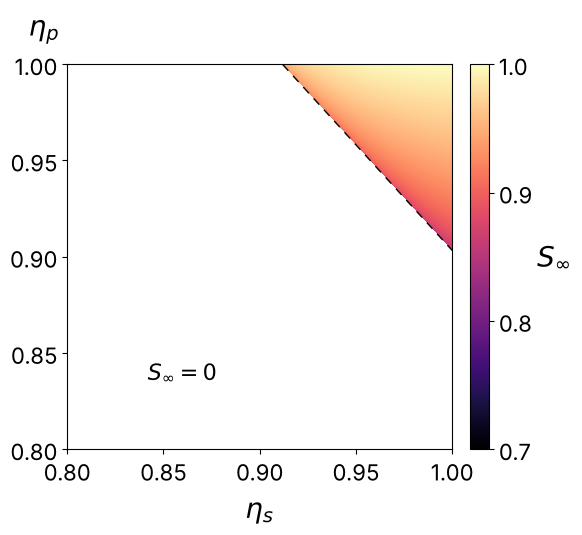

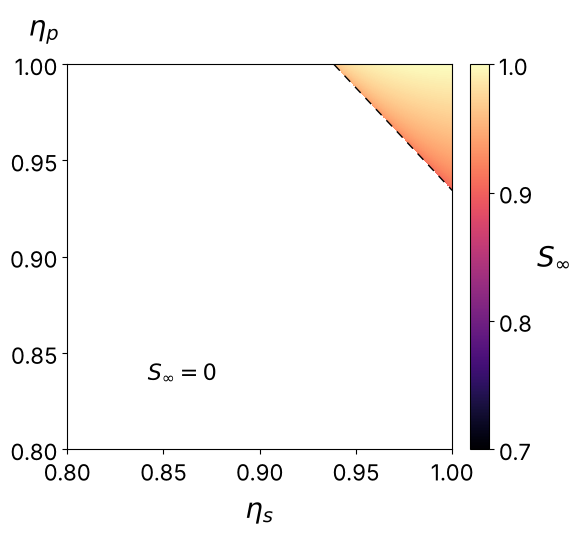

In [12]:
plot_S_inf_map(2, 3, fname="flower23.png")
plot_S_inf_map(2, 4, fname="flower24.png")
plt.show()

## 8. Fig. S2: critical slowing down (`CSD_scaling.png`)

fitted exponent (eps <= 3e-4): -0.5014
offset n_num - n_x: [-2.23 -2.81 -2.86 -2.28 -2.92 -2.08 -2.89 -2.23 -2.49 -2.21 -2.49]


saved figures/CSD_scaling.png


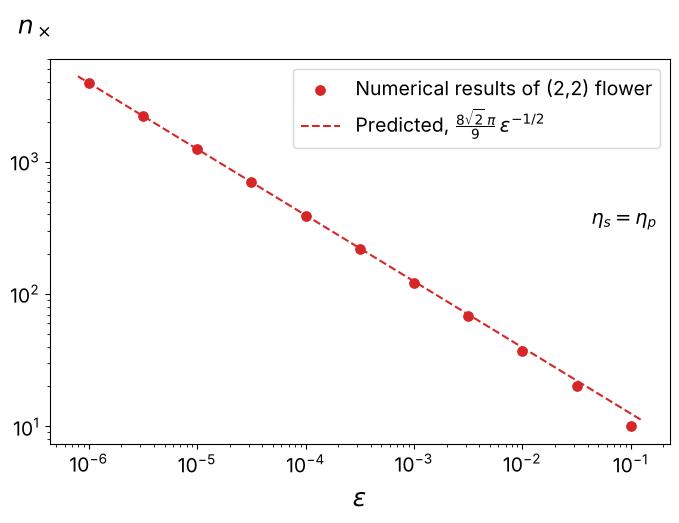

In [13]:
# Figure S2 (CSD_scaling.png): critical slowing down below the boundary (Section S2.3).
# For points on eta_s = eta_p just below the boundary, count the generation at which S_n first
# falls below half of 3/(4 eta_s), and compare with n_x = (8 sqrt2 pi / 9) eps^(-1/2),
# eps = (2 - eta_p)/eta_s - 32/27.
PREF_CSD = 8 * np.sqrt(2) * np.pi / 9


def generations_survived(eta_s, eta_p, n_max=10**6):
    S, target = 1.0, 0.5 * 3.0 / (4.0 * eta_s)
    for n in range(1, n_max + 1):
        S = survival_map(S, eta_s, eta_p)
        if S < target:
            return n
    raise RuntimeError("no collapse within n_max generations")


eps_vals = np.logspace(-6, -1, 11)
eta_diag = 2.0 / (1.0 + 32 / 27 + eps_vals)          # solves (2 - eta)/eta = 32/27 + eps
n_num = np.array([generations_survived(e, e) for e in eta_diag])
close = eps_vals <= 3e-4
print("fitted exponent (eps <= 3e-4):", round(np.polyfit(np.log(eps_vals[close]), np.log(n_num[close]), 1)[0], 4))
print("offset n_num - n_x:", np.round(n_num - PREF_CSD / np.sqrt(eps_vals), 2))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(eps_vals, n_num, color=RED, s=45, label="Numerical results of (2,2) flower", zorder=3)
e_line = np.logspace(-6.1, -0.9, 200)
ax.plot(e_line, PREF_CSD * e_line ** -0.5, "--", color=RED, lw=1.5,
        label=r"Predicted, $\frac{8\sqrt{2}\,\pi}{9}\,\epsilon^{-1/2}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$\epsilon$")
corner_ylabel(ax, r"$n_\times$", fs=18, x=-0.02, y=1.05)
ax.legend(loc="upper right", frameon=True)
ax.text(0.98, 0.62, r"$\eta_s=\eta_p$", transform=ax.transAxes, ha="right", va="top",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
save(fig, "CSD_scaling.png")
plt.show()

## 9. Fig. S3 and Table S1: mean-field and second-order closures (`f7.png`, `f9.png`)

Fig. S3(a) uses the colour scale of Fig. 4(b).

saved figures/f7.png


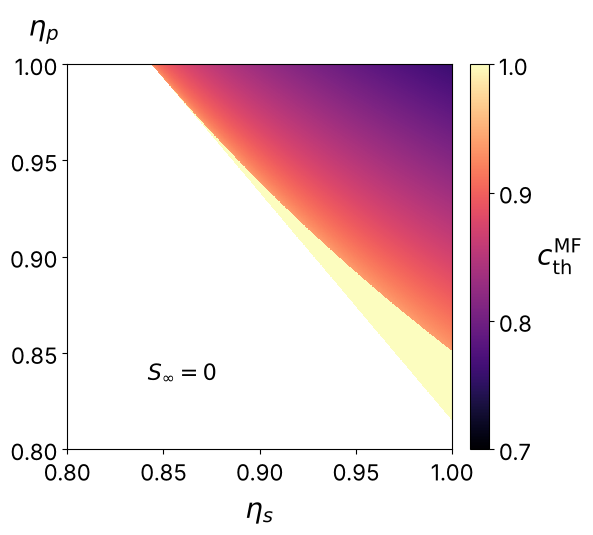

saved figures/f9.png


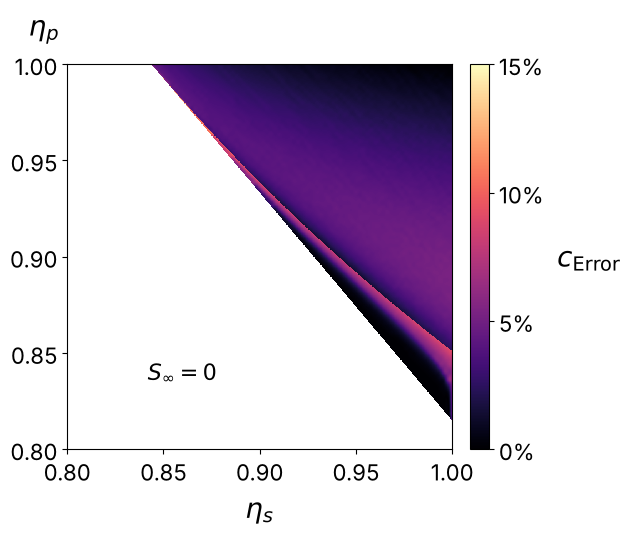

mean-field error: median 3.40%, max 13.3%


In [14]:
# Mean-field threshold c_th^MF (Supplementary Materials, Section S3, Fig. S3(a) -> f7.png)
def c_th_mean_field(eta_s, eta_p, U=2, V=2, n_bisect=100, y_probe=1.0 - 1e-6):
    """Unstable fixed point of the mean-field map, Eq. (S15), with S_n replaced by S_inf.
    Returns 1 where no interior fixed point exists (the artefact band) and nan where S_inf = 0."""
    S = S_inf(eta_s, eta_p, U, V)
    alive = S > 1e-15
    Ssafe = np.where(alive, S, 1.0)
    PU, PV = eta_s ** (U - 1) * Ssafe ** U, eta_s ** (V - 1) * Ssafe ** V
    w = np.stack([eta_p * PU * PV, PU * (1 - PV), PV * (1 - PU)])
    w = w / np.where(w.sum(0) > 0, w.sum(0), 1.0)
    G = lambda y, w: w[0] * P_hat(y ** U, y ** V) + w[1] * y ** U + w[2] * y ** V - y
    c = np.full(np.shape(S), np.nan)
    interior = alive & (G(np.full(np.shape(S), y_probe), w) > 1e-14)
    c[alive & ~interior] = 1.0
    wi = w[:, interior]
    lo, hi = np.full(wi.shape[1], 1e-12), np.full(wi.shape[1], y_probe)
    for _ in range(n_bisect):
        mid = 0.5 * (lo + hi)
        up = G(mid, wi) > 0
        hi[up], lo[~up] = mid[up], mid[~up]
    c[interior] = 0.5 * (lo + hi)
    return c


CTH_MF_FINE = c_th_mean_field(*np.meshgrid(ES_FINE, EP_FINE, indexing="xy"))
CTH_MF_FINE[np.isnan(CTH_FINE)] = np.nan
fig, ax, pc, cbar = heatmap(CTH_MF_FINE, ES_FINE, EP_FINE, 0.7, 1.0)      # same colour scale as Fig. 4(b)
cbar.set_ticks(np.arange(0.7, 1.0 + 1e-9, 0.1))
side_cbar_label(fig, cbar, r"$c^{\rm MF}_{\rm th}$")
ax.text(0.86, 0.84, r"$S_\infty = 0$", fontsize=TICK_FS, ha="center", va="center")
save(fig, "f7.png")
plt.show()

# Fig. S3(b) (f9.png): percentage deviation of the mean-field threshold from the full numerics
ERR = 100.0 * np.abs(CTH_MF_FINE - CTH_FINE) / CTH_FINE
vmax = 5.0 * np.ceil(np.nanmax(ERR) / 5.0)
fig, ax, pc, cbar = heatmap(ERR, ES_FINE, EP_FINE, 0.0, vmax)
cbar.set_ticks(np.arange(0, vmax + 1e-9, 5.0))
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
side_cbar_label(fig, cbar, r"$c_{\rm Error}$", dx=0.68)
ax.text(0.86, 0.84, r"$S_\infty = 0$", fontsize=TICK_FS, ha="center", va="center")
save(fig, "f9.png")
plt.show()
print(f"mean-field error: median {np.nanmedian(ERR):.2f}%, max {np.nanmax(ERR):.1f}%")

In [15]:
# Table S1: mean-field and second-order closures iterated to n = 50, compared with c_th from
# the full distribution (Supplementary Materials, Section S3).
def iterate_mean_field(c0, eta_s, eta_p, n=50):
    S, Y = 1.0, c0
    for _ in range(n):
        p, S_next = eta_s * S ** 2, survival_map(S, eta_s, eta_p)
        Y = (2 * p * (1 - p) * Y ** 2 + eta_p * p ** 2 * P_hat(Y ** 2, Y ** 2)) / S_next
        S = S_next
    return float(Y)


def _laplacian(g, m, h=1e-4):
    """d^2/da^2 + d^2/db^2 of g(a, b) at (m, m)."""
    m = min(max(m, 2 * h), 1 - 2 * h)
    return ((g(m + h, m) - 2 * g(m, m) + g(m - h, m)) + (g(m, m + h) - 2 * g(m, m) + g(m, m - h))) / h ** 2


def iterate_second_order(c0, eta_s, eta_p, n=50):
    """Track Y_n and Q_n = E[X_n^2 | X_n > 0]; expand P_hat to second order about the branch mean."""
    S, Y, Q = 1.0, c0, c0 ** 2
    P2 = lambda a, b: P_hat(a, b) ** 2
    for _ in range(n):
        p, S_next = eta_s * S ** 2, survival_map(S, eta_s, eta_p)
        mu, var = Y ** 2, max(Q ** 2 - Y ** 4, 0.0)
        EP = min(max(float(P_hat(mu, mu)) + 0.5 * var * _laplacian(P_hat, mu), 0.0), 1.0)
        EP2 = min(max(float(P2(mu, mu)) + 0.5 * var * _laplacian(P2, mu), EP ** 2), EP)
        Y, Q = ((2 * p * (1 - p) * mu + eta_p * p ** 2 * EP) / S_next,
                (2 * p * (1 - p) * Q ** 2 + eta_p * p ** 2 * EP2) / S_next)
        S = S_next
    return float(Y)


def closure_threshold(run, eta_s, eta_p):
    lo, hi = 0.3, 1.0
    while hi - lo > 1e-6:
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if run(mid, eta_s, eta_p) > 0.5 else (mid, hi)
    return 0.5 * (lo + hi)


TABLE_POINTS = [(0.99, 0.99), (0.95, 0.95), (0.90, 0.9513), (0.93, 0.9164), (0.90, 0.9378), (0.96, 0.8814)]
rows = []
for es_, ep_ in TABLE_POINTS:
    c = c_th_pmf(es_, ep_, c_guess=0.5, **CTH_SETTINGS)
    mf = closure_threshold(iterate_mean_field, es_, ep_)
    so = closure_threshold(iterate_second_order, es_, ep_)
    rows.append({"eta_s": es_, "eta_p": ep_, "eps": (2 - ep_) / es_ - 32 / 27, "c_th": round(c, 3),
                 "mean field (%)": round(100 * (mf - c) / c, 2), "second order (%)": round(100 * (so - c) / c, 2)})
table_S1 = pd.DataFrame(rows)
table_S1

,eta_s,eta_p,eps,c_th,mean field (%),second order (%)
0,0.99,0.9900,-0.164983,0.771,0.12,-0.03
1,0.95,0.9500,-0.079922,0.821,0.20,-0.19
2,0.90,0.9513,-0.019963,0.869,-1.20,3.86
3,0.93,0.9164,-0.020024,0.893,-3.18,0.80
4,0.90,0.9378,-0.004963,0.927,-5.86,-2.11
5,0.96,0.8814,-0.019977,0.935,-6.37,-4.10


## 10. Fig. S4: convergence of $\mathbb{E}[X_n]$ to $S_\infty$ (`EXn_scaling.png`)

S_inf = 0.938218;  fitted exponent (n >= 11) = -0.7740


saved figures/EXn_scaling.png


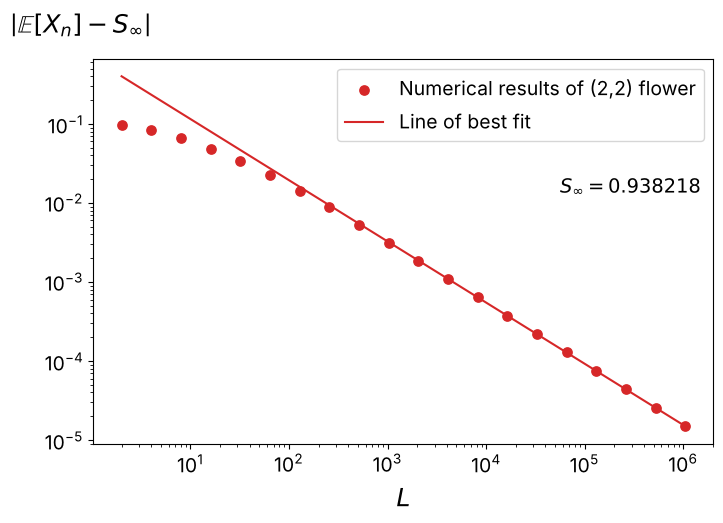

In [16]:
# Figure S4 (EXn_scaling.png): convergence of E[X_n] to S_inf, now up to L = 2^20 ~ 10^6
C0_EXN, ETA_EXN, N_MAX_EXN, FIT_FROM_N = 0.85, 0.95, 20, 11
S_INF_EXN = S_inf(ETA_EXN, ETA_EXN)
ns, devs = [], []
for n, idx, p, p0 in pmf_evolution(C0_EXN, ETA_EXN, ETA_EXN, N_MAX_EXN, n_bins=2001, p_min=0.0):
    if n >= 1:
        ns.append(n)
        devs.append(abs(pmf_mean(idx, p, 2001) - S_INF_EXN))
ns, devs = np.array(ns), np.array(devs)
Ls = 2.0 ** ns
fit = ns >= FIT_FROM_N
slope, intercept = np.polyfit(np.log10(Ls[fit]), np.log10(devs[fit]), 1)
print(f"S_inf = {S_INF_EXN:.6f};  fitted exponent (n >= {FIT_FROM_N}) = {slope:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(Ls, devs, color=RED, s=45, label="Numerical results of (2,2) flower", zorder=3)
x_line = np.logspace(np.log10(Ls.min()), np.log10(Ls.max()), 200)
ax.plot(x_line, 10 ** (intercept + slope * np.log10(x_line)), color=RED, lw=1.5, label="Line of best fit")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$L$")
corner_ylabel(ax, r"$\left|\mathbb{E}[X_n]-S_\infty\right|$", fs=18, x=-0.02, y=1.05)
ax.legend(loc="upper right", frameon=True)
ax.text(0.98, 0.70, rf"$S_\infty={S_INF_EXN:.6f}$", transform=ax.transAxes, ha="right", va="top",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
save(fig, "EXn_scaling.png")
plt.show()

## 11. Values quoted in the text

In [17]:
# Values quoted in the main text and Supplementary Materials
print("Boundary end points: (27/32, 1) =", (27 / 32, 1.0), "  (1, 22/27) =", (1.0, round(22 / 27, 4)))
print("Equal reliabilities: eta_c = 54/59 =", round(54 / 59, 4))
print("S_inf on the boundary, 3/(4 eta_s): from", round(3 / (4 * 27 / 32), 4), "to", 3 / 4)
print("S_inf(0.95, 0.95) =", round(S_inf(0.95, 0.95), 6))
print("ideal c_th =", round(C_TH_IDEAL, 15))
print("c_th(0.95, 0.95) from the n = 50 grid =", cth_df.loc[np.isclose(cth_df.eta_s, 0.95) & np.isclose(cth_df.eta_p, 0.95), "c_th_pmf"].item())

# Section S2.1: critical equal reliability for longer flowers
for U, V in [(2, 2), (2, 3), (2, 4)]:
    lo, hi = 0.5, 1.0
    for _ in range(50):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if S_inf(mid, mid, U, V) > 1e-6 else (mid, hi)
    print(f"({U},{V})-flower: critical eta_s = eta_p = {hi:.3f}")

# Distribution section: below the boundary, S_10 at eta = 0.90
S = 1.0
for n in range(10):
    S = survival_map(S, 0.90, 0.90)
print("S_10(0.90, 0.90) =", round(S, 4))

# Critical slowing down example: eta_s = eta_p = 0.91
eps_091 = (2 - 0.91) / 0.91 - 32 / 27
print(f"eta = 0.91: eps = {eps_091:.4f}, predicted generations = {PREF_CSD / np.sqrt(eps_091):.1f}")
S, traj = 1.0, []
for n in range(40):
    S = survival_map(S, 0.91, 0.91); traj.append(S)
print("  S_10 =", round(traj[9], 3), " S_20 =", round(traj[19], 3), " S_23 =", round(traj[22], 4), " S_35 =", round(traj[34], 3),
      " last n with S_n >= 3/4:", max(i + 1 for i, s in enumerate(traj) if s >= 0.75))
for c0 in (0.99, 0.85):
    n_eval = 20 if c0 == 0.99 else 10
    idx, p, p0 = pmf_at(c0, 0.91, 0.91, n_eval, n_bins=2001, p_min=1e-12)
    x = idx / 2000
    print(f"  c0 = {c0}: P(X_{n_eval} >= 0.9) = {p[x >= 0.9].sum():.3f},  E[X_{n_eval}] = {np.sum(x * p):.4f}")

Boundary end points: (27/32, 1) = (0.84375, 1.0)   (1, 22/27) = (1.0, 0.8148)
Equal reliabilities: eta_c = 54/59 = 0.9153
S_inf on the boundary, 3/(4 eta_s): from 0.8889 to 0.75
S_inf(0.95, 0.95) = 0.938218
ideal c_th = 0.759470997087017
c_th(0.95, 0.95) from the n = 50 grid = 0.8206249999999995


(2,2)-flower: critical eta_s = eta_p = 0.915


(2,3)-flower: critical eta_s = eta_p = 0.954


(2,4)-flower: critical eta_s = eta_p = 0.968
S_10(0.90, 0.90) = 0.7625
eta = 0.91: eps = 0.0126, predicted generations = 35.2
  S_10 = 0.828  S_20 = 0.78  S_23 = 0.7568  S_35 = 0.054  last n with S_n >= 3/4: 23


  c0 = 0.99: P(X_20 >= 0.9) = 0.722,  E[X_20] = 0.7626


  c0 = 0.85: P(X_10 >= 0.9) = 0.000,  E[X_10] = 0.0124


## 12. Physical Review version: `figures2/` (for `APS1.tex`)

All main-text figures re-drawn at their printed size (column width 246 pt, text width 510 pt) so that lettering is
at least 2 mm high (8 pt), data points at least 1 mm across and lines at least 0.5 pt, as required by the APS
figure guidelines. Panel labels sit inside the
axes. Figs. 3 and 4 (`fig3.pdf`, `fig4.pdf`) span one column; Fig. 5 (`fig5.pdf`) spans both columns, with one row
per regime (labeled by $\eta_s=\eta_p$ and by $c_0$ relative to $c_{\rm th}$) and one column per generation, delta
functions in the $n\to\infty$ column drawn as stems ending in dots, gray for probability exactly at $X_n = 0$ and red
for surviving connections.

saved figures2/fig3.pdf


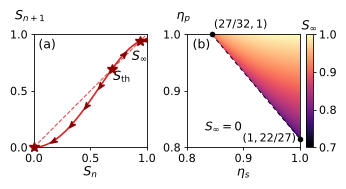

saved figures2/fig4.pdf


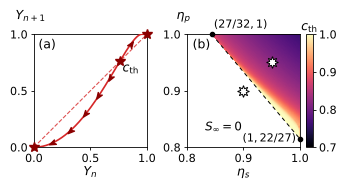

saved figures2/fig5.pdf


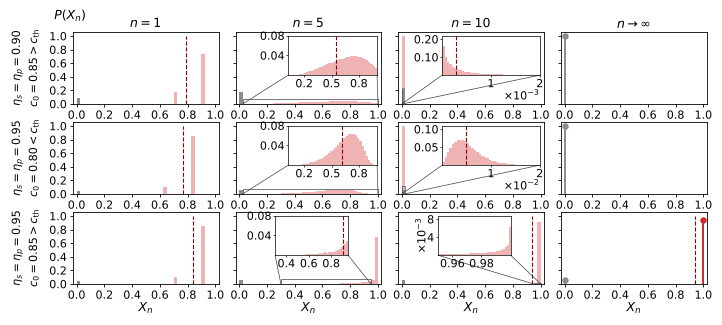

In [18]:
# Physical Review (APS1.tex) versions of Figs. 3-5, drawn at their printed size so that lettering and
# line widths meet the APS figure guidelines (lettering >= 2 mm, lines >= 0.5 pt). Panel labels sit inside
# the axes. Files are written to figures2/ as PDF (vector; the heat maps are embedded as images).
APS_DIR = "figures2"
os.makedirs(APS_DIR, exist_ok=True)
IN_COL, IN_TEXT = 246 / 72.27, 510 / 72.27               # REVTeX reprint column and text widths (inches)
A_TICK, A_LABEL, A_PANEL, A_SMALL, A_INSET = 8, 9, 9, 8, 8   # >= 8 pt: digit height >= 2 mm
APS_RC = {"font.size": A_TICK, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
          "xtick.major.size": 2.5, "ytick.major.size": 2.5, "xtick.major.pad": 2, "ytick.major.pad": 2,
          "xtick.labelsize": A_TICK, "ytick.labelsize": A_TICK, "pdf.fonttype": 42, "savefig.dpi": 600,
          "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans"}


def aps_save(fig, name):
    """Save a printed-size figure as a vector PDF in figures2/."""
    path = os.path.join(APS_DIR, name + ".pdf")
    fig.savefig(path)
    print("saved", path)


def axes_in(fig, left, bottom, width, height):
    """Axes placed in inches from the lower-left corner of the figure."""
    W, H = fig.get_size_inches()
    return fig.add_axes([left / W, bottom / H, width / W, height / H])


def panel_label(ax, text, x=0.04, y=0.96):
    ax.text(x, y, text, transform=ax.transAxes, fontsize=A_PANEL, ha="left", va="top", zorder=10)


def aps_flow(ax, F, fixed, labels, offsets, var):
    """Recursion map (solid) against the identity (dashed), fixed points as stars and the direction of
    the flow as arrowheads on the curve."""
    x = np.linspace(0.0, 1.0, 4001)
    y = F(x)
    ax.plot(x, x, color=RED, ls="--", lw=0.8, alpha=0.8, zorder=2)
    ax.plot(x, y, color=RED, lw=1.2, zorder=3)
    fp = np.array(fixed, float)
    ax.plot(fp, fp, ls="none", marker="*", ms=7.5, color=DARKRED, zorder=7, clip_on=False)
    add_arrowheads(ax, x, y, F, fp, spacing=0.2, gap=0.07, size=4.6)
    for (val, text), (dx, dy) in zip(labels, offsets):
        ax.text(val + dx, val + dy, text, fontsize=A_LABEL, ha="center", va="center")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    t = [0.0, 0.5, 1.0]
    ax.set_xticks(t); ax.set_yticks(t)
    ax.set_xticklabels([f"{v:.1f}" for v in t]); ax.set_yticklabels([f"{v:.1f}" for v in t])
    ax.set_xlabel(rf"${var}_n$", fontsize=A_LABEL, labelpad=1)
    corner_ylabel(ax, rf"${var}_{{n+1}}$", fs=A_LABEL, x=-0.03, y=1.10)


def aps_heat(ax, cax, Z, es, ep, vmin, vmax, clabel):
    """Heat map over the (eta_s, eta_p) square with the exact boundary (dashed) and its end points."""
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("white")
    pc = ax.pcolormesh(es, ep, np.ma.masked_invalid(Z), shading="nearest", cmap=cmap, vmin=vmin, vmax=vmax,
                       rasterized=True)
    ax.set_xlim(ETA_MIN, ETA_MAX); ax.set_ylim(ETA_MIN, ETA_MAX)
    t = [0.8, 0.9, 1.0]
    ax.set_xticks(t); ax.set_yticks(t)
    ax.set_xticklabels([f"{v:.1f}" for v in t]); ax.set_yticklabels([f"{v:.1f}" for v in t])
    ax.set_xlabel(r"$\eta_s$", fontsize=A_LABEL, labelpad=1)
    corner_ylabel(ax, r"$\eta_p$", fs=A_LABEL, x=-0.03, y=1.10)
    bs = np.linspace(27 / 32, 1.0, 400)
    ax.plot(bs, boundary_22(bs), color="black", ls=(0, (4, 3.5)), lw=0.7, zorder=4)
    for (x, y), txt, (dx, dy), ha, va in (((27 / 32, 1.0), r"$(27/32,1)$", (0.004, 0.006), "left", "bottom"),
                                          ((1.0, 22 / 27), r"$(1,22/27)$", (-0.006, 0.0), "right", "center")):
        ax.plot(x, y, "o", color="black", ms=3.0, zorder=5, clip_on=False)      # >= 1 mm data points
        ax.text(x + dx, y + dy, txt, fontsize=A_SMALL, ha=ha, va=va)
    ax.text(0.865, 0.835, r"$S_\infty=0$", fontsize=A_LABEL - 0.5, ha="center", va="center")
    cb = plt.colorbar(pc, cax=cax)
    cb.set_ticks(np.arange(vmin, vmax + 1e-9, 0.1))
    cb.ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.1f"))
    cb.outline.set_linewidth(0.6)
    cb.ax.tick_params(labelsize=A_TICK, width=0.6, length=2)
    cax.set_title(clabel, fontsize=A_LABEL, pad=3)
    return pc


def aps_pair(fig_name, flow_args, heat_args, star_points=()):
    """Figs. 3 and 4: flow (a) and heat map (b) side by side across one column."""
    W, H = IN_COL, 1.80
    a, bot = 1.13, 0.36
    with plt.rc_context(APS_RC):
        fig = plt.figure(figsize=(W, H))
        ax1 = axes_in(fig, 0.29, bot, a, a)
        ax2 = axes_in(fig, 0.29 + a + 0.40, bot, a, a)
        cax = axes_in(fig, 0.29 + 2 * a + 0.40 + 0.06, bot, 0.075, a)
        aps_flow(ax1, *flow_args)
        aps_heat(ax2, cax, *heat_args)
        for x, y in star_points:
            ax2.plot(x, y, marker=STAR8, ms=8.5, mfc="white", mec="black", mew=0.7, ls="none", zorder=6)
        panel_label(ax1, "(a)"); panel_label(ax2, "(b)", x=0.05)
        aps_save(fig, fig_name)
    return fig


_es = np.linspace(ETA_MIN, ETA_MAX, 1001)
_ES, _EP = np.meshgrid(_es, _es, indexing="xy")
S_INF_MAP = S_inf(_ES, _EP)
S_INF_MAP = np.where(S_INF_MAP > 1e-12, S_INF_MAP, np.nan)
aps_pair("fig3",
         (F_S, [0.0, S_th, S_star], [(S_th, r"$S_{\rm th}$"), (S_star, r"$S_\infty$")],
          [(0.09, -0.07), (0.0, -0.14)], "S"),
         (S_INF_MAP, _es, _es, 0.7, 1.0, r"$S_\infty$"))
plt.show()
aps_pair("fig4",
         (F_Y, [0.0, C_TH_IDEAL, 1.0], [(C_TH_IDEAL, r"$c_{\rm th}$")], [(0.10, -0.06)], "Y"),
         (np.clip(CTH_FINE, 0.7, 1.0), ES_FINE, EP_FINE, 0.7, 1.0, r"$c_{\rm th}$"),
         star_points=FIG5_POINTS)
plt.show()


# ---------------------------------------------------------------- Fig. 5
# Rows: regimes, from below the operational threshold (top) to above both thresholds (bottom).
# Columns: n = 1, 5, 10 and the large-network limit. Grey: probability exactly at X_n = 0 (complete
# failure); red: surviving connections, X_n > 0, which may lie arbitrarily close to zero.
APS5_ROWS = [0, 1, 2]                                    # indices into PMF_DATA
APS5_LABEL = {"below": [r"$\eta_s=\eta_p=%.2f$", r"$c_0=%.2f>c_{\rm th}$"],      # two lines per row:
              "between": [r"$\eta_s=\eta_p=%.2f$", r"$c_0=%.2f<c_{\rm th}$"],    # operations, then c_0
              "above": [r"$\eta_s=\eta_p=%.2f$", r"$c_0=%.2f>c_{\rm th}$"]}      # relative to c_th


def aps_pow(axin, axis, k):
    unit = 10.0 ** k
    fmt = plt.FuncFormatter(lambda v, _: f"{v / unit:g}")
    text = rf"$\times10^{{{k}}}$"
    if axis == "x":
        axin.xaxis.set_major_formatter(fmt)
        axin.annotate(text, xy=(1.0, 0.0), xycoords="axes fraction", xytext=(0, -10), textcoords="offset points",
                      ha="right", va="top", fontsize=A_INSET)
    else:
        axin.yaxis.set_major_formatter(fmt)
        axin.annotate(text, xy=(0.0, 0.5), xycoords="axes fraction", xytext=(-11.5, 0), textcoords="offset points",
                      ha="center", va="center", rotation=90, fontsize=A_INSET)


def aps_zoom(ax, idx, p, mean, x, y, box, xticks, yticks, xpow=None, ypow=None, exclude=None):
    edges = np.linspace(x[0], x[1], N_ZOOM_BINS + 1)
    if exclude == "X=1":
        keep = GRID_PMF[idx] < 1.0
        idx, p = idx[keep], p[keep]
    mass = binned(idx, p, edges)
    axin = ax.inset_axes(box)
    draw_bars(axin, edges, mass)
    if x[0] <= mean <= x[1]:
        axin.vlines(mean, 0.0, y[1], linestyles="--", colors=MEAN_C, lw=0.8, zorder=3)
    else:
        ax.vlines(mean, 0.0, 1.0, linestyles="--", colors=MEAN_C, lw=0.8, zorder=3)
    axin.set_xlim(*x); axin.set_ylim(*y)
    axin.tick_params(labelsize=A_INSET, length=1.6, pad=1, width=0.5)
    for s in axin.spines.values():
        s.set_linewidth(0.5)
    axin.set_xticks(xticks); axin.set_yticks(yticks)
    if xpow is None:
        axin.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f" if x[1] - x[0] < 0.1 else "%.1f"))
    else:
        aps_pow(axin, "x", xpow)
    if ypow is None:
        axin.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
    else:
        aps_pow(axin, "y", ypow)
    ax.add_patch(plt.Rectangle((x[0], y[0]), x[1] - x[0], y[1] - y[0], fill=False, edgecolor="0.25", lw=0.5,
                               zorder=4))
    for xa, xb in ((x[0], 0.0), (x[1], 1.0)):
        ax.add_artist(ConnectionPatch(xyA=(xa, y[0]), coordsA=ax.transData, xyB=(xb, 0.0), coordsB=axin.transAxes,
                                      color="0.25", lw=0.5, zorder=4))


def lollipop(ax, x, h, color):
    """Delta function of weight h at x: a stem ending in a dot."""
    ax.vlines(x, 0.0, h, colors=color, lw=1.4, zorder=5)
    ax.plot(x, h, "o", color=color, ms=3.6, zorder=6, clip_on=False)


def aps_limit(ax, s_inf, regime):
    if regime in ("below", "between"):                   # all probability exactly at X = 0 (grey)
        lollipop(ax, 0.0, 1.0, FAIL_C)
    else:                                                # binary limit
        lollipop(ax, 0.0, 1.0 - s_inf, FAIL_C)
        lollipop(ax, 1.0, s_inf, SURV_C)
        ax.vlines(s_inf, 0.0, 1.0, linestyles="--", colors=MEAN_C, lw=0.8, zorder=3)


# inset placement for the printed size (axes fractions), keyed by (regime index, n)
APS5_BOX = {(0, 5): (0.36, 0.40, 0.61, 0.55), (1, 5): (0.36, 0.40, 0.61, 0.55), (2, 5): (0.27, 0.40, 0.50, 0.55),
            (0, 10): (0.30, 0.40, 0.67, 0.55), (1, 10): (0.30, 0.40, 0.67, 0.55), (2, 10): (0.27, 0.40, 0.50, 0.55)}
APS5_XTICKS = {(0, 5): [0.2, 0.5, 0.8], (1, 5): [0.2, 0.5, 0.8]}   # fewer inset ticks, so 8 pt labels do not touch


def aps_fig5(name="fig5"):
    W = IN_TEXT
    left, right, top, bottom = 0.68, 0.04, 0.26, 0.36
    gx, gy = 0.17, 0.18
    w = (W - left - right - 3 * gx) / 4
    h = 0.72
    H = bottom + 3 * h + 2 * gy + top
    with plt.rc_context(APS_RC):
        fig = plt.figure(figsize=(W, H))
        for r, k in enumerate(APS5_ROWS):
            eta, c0, zooms, snaps, s_inf, regime = PMF_DATA[k]
            for g, n in enumerate(GENS + [None]):
                ax = axes_in(fig, left + g * (w + gx), bottom + (2 - r) * (h + gy), w, h)
                if g == 0:
                    ax0 = ax
                if n is None:
                    aps_limit(ax, s_inf, regime)
                else:
                    idx, p, p0 = snaps[n]
                    mean = float(np.sum(GRID_PMF[idx] * p))
                    draw_bars(ax, EDGES, binned(idx, p, EDGES), p0)
                    if n in zooms:
                        spec = dict(zooms[n]); spec["box"] = APS5_BOX[(k, n)]
                        spec["xticks"] = APS5_XTICKS.get((k, n), spec["xticks"])
                        aps_zoom(ax, idx, p, mean, **spec)
                    else:
                        ax.vlines(mean, 0.0, 1.0, linestyles="--", colors=MEAN_C, lw=0.8, zorder=3)
                ax.set_xlim(-BIN_W, 1.0 + BIN_W); ax.set_ylim(0.0, 1.06)
                t = np.linspace(0, 1, 6)
                ax.set_xticks(t); ax.set_yticks(t)
                ax.set_xticklabels([f"{v:.1f}" for v in t])
                ax.set_yticklabels([f"{v:.1f}" for v in t] if g == 0 else [])
                if r == 2:
                    ax.set_xlabel(r"$X_n$", fontsize=A_LABEL, labelpad=0.5)
                if g == 0 and r == 0:
                    corner_ylabel(ax, r"$P(X_n)$", fs=A_LABEL, x=-0.02, y=1.13)
                if r == 0:
                    ax.set_title(rf"$n={n}$" if n is not None else r"$n\to\infty$", fontsize=A_LABEL, pad=3)
            lines = APS5_LABEL[regime]
            text = "\n".join([lines[0] % eta, lines[1] % c0] + lines[2:])
            ax0.annotate(text, xy=(-0.47 / w, 0.5), xycoords="axes fraction", rotation=90, ha="center", va="center",
                         fontsize=A_SMALL, linespacing=1.45)
        aps_save(fig, name)
    return fig


aps_fig5()
plt.show()

The schematics, Fig. 1 (`fig1.pdf`, full width) and Fig. 2 (`fig2.pdf`, one column, the three outcomes of one
renormalization step flowing downwards), are drawn with the same primitives so that every arrow has the same style.

saved figures2/fig1.pdf


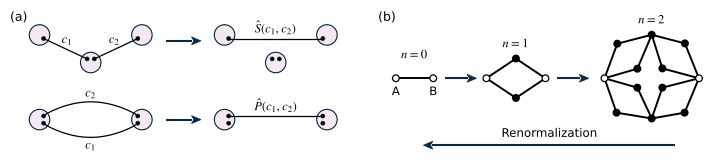

saved figures2/fig2.pdf


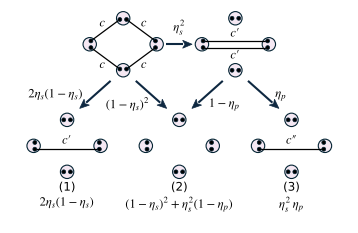

In [19]:
# Schematics, Figs. 1 and 2 (fig1.pdf, fig2.pdf in figures2/), drawn at their printed size; lengths in cm.
# Nodes are pale discs with their qubits as small solid black dots; every arrow has the same style.
from matplotlib.patches import Circle, Polygon

CM = 1 / 2.54
NODE_FC, NODE_EC, ARROW_C = "#f5e8f3", "#042433", "#0e2841"
R, QR = 0.17, 0.050                 # node and qubit radii (cm); qubits 1 mm across
LW_NODE, LW_LINK, LW_ARROW = 0.8, 0.9, 1.5
MATH_FS, TEXT_FS = 9, 8.5


def canvas(w, h):
    fig = plt.figure(figsize=(w * CM, h * CM))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, w); ax.set_ylim(0, h); ax.set_aspect("equal"); ax.axis("off")
    return fig, ax


def node(ax, x, y, qubits, r=R, open_=False):
    """Node at (x, y) with qubits at the given offsets (in units of r)."""
    if open_:
        ax.add_patch(Circle((x, y), 0.07, fc="white", ec="black", lw=0.8, zorder=4))
        return
    ax.add_patch(Circle((x, y), r, fc=NODE_FC, ec=NODE_EC, lw=LW_NODE, zorder=2))
    for dx, dy in qubits:
        ax.add_patch(Circle((x + dx * r, y + dy * r), QR, fc="black", ec=NODE_EC, lw=0.5, zorder=4))


def q(x, y, dx, dy, r=R):
    return (x + dx * r, y + dy * r)


def line(ax, p, q_, lw=LW_LINK, **kw):
    ax.plot([p[0], q_[0]], [p[1], q_[1]], color="black", lw=lw, solid_capstyle="round", zorder=3, **kw)


def arrow(ax, p, q_, lw=LW_ARROW, head=0.24):
    """Dark arrow with a filled triangular head of length `head` (cm); the same style everywhere."""
    p, q_ = np.asarray(p, float), np.asarray(q_, float)
    d = q_ - p
    L = np.hypot(*d)
    u = d / L
    nrm = np.array([-u[1], u[0]])
    base = q_ - u * head
    ax.plot(*zip(p, base + u * 0.02), color=ARROW_C, lw=lw, solid_capstyle="butt", zorder=5)
    hw = 0.42 * head
    ax.add_patch(Polygon([q_, base + nrm * hw, base + u * 0.25 * head, base - nrm * hw], closed=True,
                         fc=ARROW_C, ec=ARROW_C, lw=0.5, zorder=5))


def label(ax, x, y, s, fs=MATH_FS, ha="center", va="center", **kw):
    ax.text(x, y, s, fontsize=fs, ha=ha, va=va, zorder=6, **kw)


# qubit offsets (units of r): each pair sits close to the centre of its node and 1.0 r apart, so the two
# 1 mm dots keep a clear gap between them and stay inside the node
QA, QB = 0.18, 0.50                          # offset towards the link side, half the separation
SIDE_R = [(QA, QB), (QA, -QB)]               # two qubits stacked, right side of a node
SIDE_L = [(-QA, QB), (-QA, -QB)]
PAIR_D = [(-QB, -QA), (QB, -QA)]             # two qubits side by side, lower part
PAIR_U = [(-QB, QA), (QB, QA)]
PAIR_C = [(-QB, 0.0), (QB, 0.0)]


HH = 0.66                                    # half-height of a motif: room for c', c'' at the link centres


def motif(ax, xc, yc, hw=0.85, hh=HH, labels=True):
    """Generation n = 1 (2,2)-flower motif: four links of concurrence c."""
    A, B, T, D = (xc - hw, yc), (xc + hw, yc), (xc, yc + hh), (xc, yc - hh)
    node(ax, *A, SIDE_R); node(ax, *B, SIDE_L); node(ax, *T, PAIR_D); node(ax, *D, PAIR_U)
    line(ax, q(*A, *SIDE_R[0]), q(*T, *PAIR_D[0])); line(ax, q(*T, *PAIR_D[1]), q(*B, *SIDE_L[0]))
    line(ax, q(*A, *SIDE_R[1]), q(*D, *PAIR_U[0])); line(ax, q(*D, *PAIR_U[1]), q(*B, *SIDE_L[1]))
    if labels:
        for sx, sy in ((-1, 1), (1, 1), (-1, -1), (1, -1)):
            label(ax, xc + sx * hw * 0.62, yc + sy * hh * 0.80, r"$c$")


def state(ax, xc, yc, kind, hw=0.85, hh=HH):
    """Motif after the series step: kind = 'none' (disconnected), 'double' (two paths c'),
    'single' (one path c'), 'parallel' (one link c'')."""
    A, B, T, D = (xc - hw, yc), (xc + hw, yc), (xc, yc + hh), (xc, yc - hh)
    node(ax, *A, SIDE_R); node(ax, *B, SIDE_L); node(ax, *T, PAIR_C); node(ax, *D, PAIR_C)
    if kind == "double":
        line(ax, q(*A, *SIDE_R[0]), q(*B, *SIDE_L[0])); line(ax, q(*A, *SIDE_R[1]), q(*B, *SIDE_L[1]))
        label(ax, xc, yc + 0.11, r"$c\prime$", va="bottom"); label(ax, xc, yc - 0.13, r"$c\prime$", va="top")
    elif kind in ("single", "parallel"):
        line(ax, q(*A, *SIDE_R[1]), q(*B, *SIDE_L[1]))
        label(ax, xc, yc - 0.03, r"$c\prime$" if kind == "single" else r"$c\prime\!\prime$", va="bottom")


with plt.rc_context({"mathtext.fontset": "stix", "pdf.fonttype": 42, "font.family": "DejaVu Sans"}):
    # ---------------- Fig. 1 (full width) ----------------
    PANEL_FS = 9
    W, H = 17.9, 3.75
    fig, ax = canvas(W, H)
    RA = 0.26                                            # node radius in panel (a)

    # ---------------- (a) series and parallel combination ----------------
    ya, yb = 2.85, 0.95                                  # rows
    xl, xr, xm = 0.75, 3.35, 2.05
    node(ax, xl, ya + 0.25, [(0.4, -0.35)], r=RA)
    node(ax, xm, ya - 0.45, [(-0.35, 0.35), (0.35, 0.35)], r=RA)
    node(ax, xr, ya + 0.25, [(-0.4, -0.35)], r=RA)
    line(ax, q(xl, ya + 0.25, 0.4, -0.35, RA), q(xm, ya - 0.45, -0.35, 0.35, RA))
    line(ax, q(xm, ya - 0.45, 0.35, 0.35, RA), q(xr, ya + 0.25, -0.4, -0.35, RA))
    label(ax, (xl + xm) / 2 + 0.05, ya + 0.12, r"$c_1$"); label(ax, (xm + xr) / 2 - 0.05, ya + 0.12, r"$c_2$")
    arrow(ax, (3.95, ya + 0.1), (4.85, ya + 0.1))
    xl2, xr2, xm2 = 5.45, 8.05, 6.75
    node(ax, xl2, ya + 0.25, [(0.4, -0.35)], r=RA); node(ax, xr2, ya + 0.25, [(-0.4, -0.35)], r=RA)
    node(ax, xm2, ya - 0.45, [(-0.35, 0.35), (0.35, 0.35)], r=RA)
    line(ax, q(xl2, ya + 0.25, 0.4, -0.35, RA), q(xr2, ya + 0.25, -0.4, -0.35, RA))
    label(ax, (xl2 + xr2) / 2, ya + 0.24, r"$\hat{S}(c_1,c_2)$", va="bottom")

    node(ax, xl, yb, [(0.4, 0.35), (0.4, -0.35)], r=RA)
    node(ax, xr, yb, [(-0.4, 0.35), (-0.4, -0.35)], r=RA)
    for sgn, lab in ((1, r"$c_2$"), (-1, r"$c_1$")):
        p0 = np.array(q(xl, yb, 0.4, 0.35 * sgn, RA)); p1 = np.array(q(xr, yb, -0.4, 0.35 * sgn, RA))
        t = np.linspace(0, 1, 60)
        xs_ = p0[0] + (p1[0] - p0[0]) * t
        ys_ = p0[1] + sgn * 0.36 * np.sin(np.pi * t) ** 0.8
        ax.plot(xs_, ys_, color="black", lw=LW_LINK, zorder=3)
        label(ax, (xl + xr) / 2, yb + sgn * 0.66, lab)
    arrow(ax, (3.95, yb), (4.85, yb))
    node(ax, xl2, yb, [(0.4, 0.35), (0.4, -0.35)], r=RA); node(ax, xr2, yb, [(-0.4, 0.35), (-0.4, -0.35)], r=RA)
    line(ax, q(xl2, yb, 0.4, 0.35, RA), q(xr2, yb, -0.4, 0.35, RA))
    label(ax, (xl2 + xr2) / 2, yb + 0.16, r"$\hat{P}(c_1,c_2)$", va="bottom")
    ax.text(0.0, H - 0.05, "(a)", fontsize=PANEL_FS, ha="left", va="top", family="DejaVu Sans")

    # ---------------- (b) the (2,2)-flower and its renormalisation ----------------
    x0b = 9.6
    yg = 2.0                                            # height of the boundary nodes
    LWB, DOT = 1.4, 0.085


    def bnode(x, y, open_=False):
        ax.add_patch(Circle((x, y), DOT, fc="white" if open_ else "black", ec="black", lw=0.9, zorder=4))


    def edges(pts, pairs):
        for i, j in pairs:
            ax.plot(*zip(pts[i], pts[j]), color="black", lw=LWB, solid_capstyle="round", zorder=3)


    # n = 0
    A0, B0 = (x0b + 0.2, yg), (x0b + 1.15, yg)
    edges([A0, B0], [(0, 1)]); bnode(*A0, True); bnode(*B0, True)
    ax.text(A0[0], yg - 0.2, "A", fontsize=TEXT_FS, ha="center", va="top")
    ax.text(B0[0], yg - 0.2, "B", fontsize=TEXT_FS, ha="center", va="top")
    label(ax, (A0[0] + B0[0]) / 2, yg + 0.42, r"$n=0$", va="bottom")
    arrow(ax, (x0b + 1.45, yg), (x0b + 2.25, yg))
    # n = 1
    c1x = x0b + 3.25
    P1 = [(c1x - 0.75, yg), (c1x, yg + 0.5), (c1x + 0.75, yg), (c1x, yg - 0.5)]
    edges(P1, [(0, 1), (1, 2), (2, 3), (3, 0)])
    bnode(*P1[0], True); bnode(*P1[2], True); bnode(*P1[1]); bnode(*P1[3])
    label(ax, c1x, yg + 0.7, r"$n=1$", va="bottom")
    arrow(ax, (c1x + 1.05, yg), (c1x + 1.85, yg))
    # n = 2 (coordinates from the generation rule: every link of n = 1 replaced by two paths of length two)
    c2x, s = c1x + 3.45, 1.2 / 302
    px = {"A": (1258, 493), "B": (1862, 493), "T": (1560, 215), "D": (1560, 750),
          "o1": (1340, 272), "o2": (1772, 270), "o3": (1770, 713), "o4": (1335, 713),
          "i1": (1468, 432), "i2": (1628, 430), "i3": (1628, 553), "i4": (1468, 553)}
    P2 = {k: (c2x + (x - 1560) * s, yg - (y - 493) * s) for k, (x, y) in px.items()}
    pairs = [("A", "o1"), ("o1", "T"), ("A", "i1"), ("i1", "T"), ("T", "o2"), ("o2", "B"), ("T", "i2"), ("i2", "B"),
             ("B", "o3"), ("o3", "D"), ("B", "i3"), ("i3", "D"), ("D", "o4"), ("o4", "A"), ("D", "i4"), ("i4", "A")]
    keys = list(P2)
    edges([P2[k] for k in keys], [(keys.index(a), keys.index(b)) for a, b in pairs])
    for k in keys:
        bnode(*P2[k], open_=k in ("A", "B"))
    label(ax, c2x, P2["T"][1] + 0.2, r"$n=2$", va="bottom")
    # renormalisation reverses the growth
    yr = 0.3
    arrow(ax, (c2x + 0.6, yr), (x0b + 0.9, yr))
    ax.text((c2x + 0.6 + x0b + 0.9) / 2, yr + 0.14, "Renormalization", fontsize=TEXT_FS, ha="center", va="bottom")
    ax.text(x0b - 0.25, H - 0.05, "(b)", fontsize=PANEL_FS, ha="left", va="top", family="DejaVu Sans")
    aps_save(fig, "fig1")
    plt.show()

    # ---------------- Fig. 2 (one column): outcomes of one stochastic renormalisation step ----------------
    W = 8.6
    xs = [1.45, 4.3, 7.15]                    # outcome columns
    xM, xD = (xs[0] + xs[1]) / 2, (xs[1] + xs[2]) / 2
    dH = HH - 0.55                            # extra half-height of the motifs
    y2 = 1.85 + dH                            # outcomes
    y1 = y2 + 2.36 + 2 * dH                   # motif and the two-path state
    H = y1 + 0.78 + dH
    fig, ax = canvas(W, H)
    motif(ax, xM, y1)
    state(ax, xD, y1, "double")
    state(ax, xs[0], y2, "single"); state(ax, xs[1], y2, "none"); state(ax, xs[2], y2, "parallel")
    arrow(ax, (xM + 1.1, y1), (xD - 1.1, y1)); label(ax, (xM + xD) / 2, y1 + 0.22, r"$\eta_s^2$", va="bottom")
    ya, yb = y1 - 0.82 - dH, y2 + 0.84 + dH  # arrows start below the motif and end above the outcomes
    a1 = ((xM - 0.32, ya), (xs[0] + 0.32, yb))
    a2 = ((xM + 0.32, ya), (xs[1] - 0.32, yb))
    a3 = ((xD - 0.32, ya), (xs[1] + 0.32, yb))
    a4 = ((xD + 0.32, ya), (xs[2] - 0.32, yb))
    for a in (a1, a2, a3, a4):
        arrow(ax, *a)


    def at(a, f):
        (x0, y0), (x1, y1_) = a
        return x0 + f * (x1 - x0), y0 + f * (y1_ - y0)


    x, y = at(a1, 0.5); label(ax, x - 0.30, y, r"$2\eta_s(1-\eta_s)$", ha="right")
    x, y = at(a2, 0.86); label(ax, x - 0.32, y, r"$(1-\eta_s)^2$", ha="right")
    x, y = at(a3, 0.86); label(ax, x + 0.32, y, r"$1-\eta_p$", ha="left")
    x, y = at(a4, 0.5); label(ax, x + 0.30, y, r"$\eta_p$", ha="left")
    PROBS2 = {1: r"$2\eta_s(1-\eta_s)$", 2: r"$(1-\eta_s)^2+\eta_s^2(1-\eta_p)$", 3: r"$\eta_s^2\,\eta_p$"}
    for x, k in zip(xs, (1, 2, 3)):
        label(ax, x, y2 - 0.8 - dH, f"({k})", fs=TEXT_FS, va="top")
        label(ax, x, y2 - 1.18 - dH, PROBS2[k], va="top")
    aps_save(fig, "fig2")
    plt.show()

## 13. Supplemental Material figures: `figures2/figS1.pdf` ... `figS4.pdf` (for `supplementary.tex`)

Figs. S1-S4 in the style of the main-text figures: same fonts and line widths, panel labels inside the axes,
heat maps on the color scale of Figs. 3(b) and 4(b). They reuse the results of Sections 7-10.

saved figures2/figS1.pdf


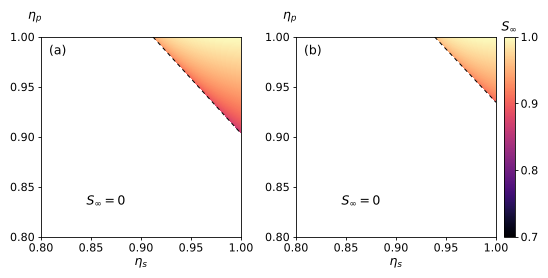

saved figures2/figS2.pdf


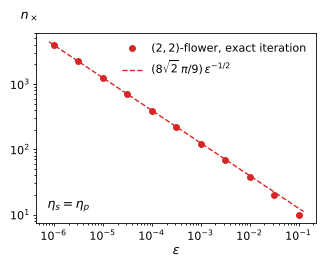

saved figures2/figS3.pdf


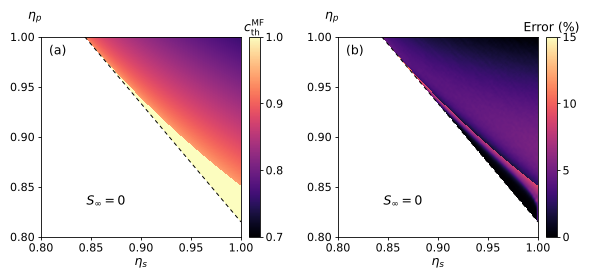

saved figures2/figS4.pdf


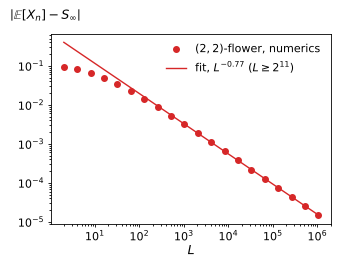

In [20]:
# Supplemental Material figures (Figs. S1-S4) in the style of the Physical Review figures: drawn at their
# printed size with the same fonts (>= 8 pt), line widths (>= 0.5 pt) and panel labels inside the axes.
# Written to figures2/ as figS1.pdf ... figS4.pdf (supplementary.tex reads them from there).
SM_PANEL = 2.0                                           # side of a square heat-map panel (inches)


def sm_heat(ax, cax, Z, es, ep, vmin, vmax, ctitle, boundary, ticks, fmt="%.1f"):
    """Heat map over the (eta_s, eta_p) square with the operational boundary dashed, as in Fig. 3(b)."""
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("white")
    pc = ax.pcolormesh(es, ep, np.ma.masked_invalid(Z), shading="nearest", cmap=cmap, vmin=vmin, vmax=vmax,
                       rasterized=True)
    ax.set_xlim(ETA_MIN, ETA_MAX); ax.set_ylim(ETA_MIN, ETA_MAX)
    t = [0.80, 0.85, 0.90, 0.95, 1.00]
    ax.set_xticks(t); ax.set_yticks(t)
    ax.set_xticklabels([f"{v:.2f}" for v in t]); ax.set_yticklabels([f"{v:.2f}" for v in t])
    ax.set_xlabel(r"$\eta_s$", fontsize=A_LABEL, labelpad=1)
    corner_ylabel(ax, r"$\eta_p$", fs=A_LABEL, x=-0.03, y=1.07)
    ax.plot(*boundary, color="black", ls=(0, (4, 3.5)), lw=0.7, zorder=4)
    ax.text(0.865, 0.835, r"$S_\infty=0$", fontsize=A_LABEL, ha="center", va="center")
    if cax is not None:
        cb = plt.colorbar(pc, cax=cax)
        cb.set_ticks(ticks)
        cb.ax.yaxis.set_major_formatter(plt.FormatStrFormatter(fmt))
        cb.outline.set_linewidth(0.6)
        cb.ax.tick_params(labelsize=A_TICK, width=0.6, length=2)
        cax.set_title(ctitle, fontsize=A_LABEL, pad=4)
    return pc


def sm_loglog(ax, xlabel, ylabel):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.tick_params(which="both", width=0.6)
    ax.tick_params(which="minor", length=1.5)
    ax.set_xlabel(xlabel, fontsize=A_LABEL, labelpad=1)
    corner_ylabel(ax, ylabel, fs=A_LABEL, x=-0.02, y=1.06)


with plt.rc_context(APS_RC):
    # Fig. S1: operational phase diagrams of the (2,3)- and (2,4)-flowers, one shared colour scale
    W, H, a, bot = 5.7, 2.74, SM_PANEL, 0.42
    fig = plt.figure(figsize=(W, H))
    es = np.linspace(ETA_MIN, ETA_MAX, 1001)
    ES_, EP_ = np.meshgrid(es, es, indexing="xy")
    for k, (V, lab) in enumerate(((3, "(a)"), (4, "(b)"))):
        ax = axes_in(fig, 0.45 + k * (a + 0.55), bot, a, a)
        cax = axes_in(fig, 0.45 + 2 * a + 0.55 + 0.08, bot, 0.11, a) if k == 1 else None
        Z = S_inf(ES_, EP_, 2, V)
        bs, bp, _ = boundary_curve(2, V)
        keep = (bp >= ETA_MIN) & (bp <= 1.0)
        sm_heat(ax, cax, np.where(Z > 1e-12, Z, np.nan), es, es, 0.7, 1.0, r"$S_\infty$",
                (bs[keep], bp[keep]), [0.7, 0.8, 0.9, 1.0])
        panel_label(ax, lab)
    aps_save(fig, "figS1")
    plt.show()

    # Fig. S2: critical slowing down below the operational phase boundary
    fig = plt.figure(figsize=(3.6, 2.6))
    ax = axes_in(fig, 0.62, 0.45, 2.8, 1.9)
    ax.plot(eps_vals, n_num, "o", color=RED, ms=4, zorder=3, label=r"$(2,2)$-flower, exact iteration")
    e_line = np.logspace(-6.1, -0.9, 200)
    ax.plot(e_line, PREF_CSD * e_line ** -0.5, "--", color=RED, lw=1.0,
            label=r"$(8\sqrt{2}\,\pi/9)\,\epsilon^{-1/2}$")
    sm_loglog(ax, r"$\epsilon$", r"$n_\times$")
    ax.legend(loc="upper right", fontsize=A_TICK, frameon=False, handlelength=1.8)
    ax.text(0.04, 0.06, r"$\eta_s=\eta_p$", transform=ax.transAxes, fontsize=A_LABEL, ha="left", va="bottom")
    aps_save(fig, "figS2")
    plt.show()

    # Fig. S3: (a) mean-field threshold, (b) its percentage deviation from the full numerics
    W, H = 6.1, 2.74
    fig = plt.figure(figsize=(W, H))
    ax1 = axes_in(fig, 0.45, bot, a, a); cax1 = axes_in(fig, 0.45 + a + 0.08, bot, 0.11, a)
    x2 = 0.45 + a + 0.08 + 0.11 + 0.78
    ax2 = axes_in(fig, x2, bot, a, a); cax2 = axes_in(fig, x2 + a + 0.08, bot, 0.11, a)
    bs = np.linspace(27 / 32, 1.0, 400)
    sm_heat(ax1, cax1, CTH_MF_FINE, ES_FINE, EP_FINE, 0.7, 1.0, r"$c^{\rm MF}_{\rm th}$",
            (bs, boundary_22(bs)), [0.7, 0.8, 0.9, 1.0])
    vmax = 5.0 * np.ceil(np.nanmax(ERR) / 5.0)
    sm_heat(ax2, cax2, ERR, ES_FINE, EP_FINE, 0.0, vmax, r"Error (%)",
            (bs, boundary_22(bs)), np.arange(0, vmax + 1e-9, 5.0), fmt="%.0f")
    panel_label(ax1, "(a)"); panel_label(ax2, "(b)")
    aps_save(fig, "figS3")
    plt.show()

    # Fig. S4: convergence of E[X_n] to S_inf above both thresholds
    fig = plt.figure(figsize=(3.6, 2.6))
    ax = axes_in(fig, 0.62, 0.45, 2.8, 1.9)
    ax.plot(Ls, devs, "o", color=RED, ms=4, zorder=3, label=r"$(2,2)$-flower, numerics")
    x_line = np.logspace(np.log10(Ls.min()), np.log10(Ls.max()), 200)
    ax.plot(x_line, 10 ** (intercept + slope * np.log10(x_line)), color=RED, lw=1.0,
            label=rf"fit, $L^{{{slope:.2f}}}$ ($L\geq2^{{{FIT_FROM_N}}}$)")
    sm_loglog(ax, r"$L$", r"$\left|\mathbb{E}[X_n]-S_\infty\right|$")
    ax.legend(loc="upper right", fontsize=A_TICK, frameon=False, handlelength=1.8)
    aps_save(fig, "figS4")
    plt.show()